# **Nivell 1**: Visualització analítica guiada en Python

L'objectiu del nivell és aplicar criteri analític per respondre preguntes de negoci mitjançant visualitzacions en Python, treballant amb les taules del model del Sprint 2 a partir de l’exercici 8, carregades com a DataFrame independents.

En aquest nivell no es demana construir un dataset final ni unificar totes les taules, sinó:

*   Identificar quina informació és necessària.
*   Escollir correctament la taula (o taules) rellevant(s).
*   Construir visualitzacions adequades.
*   Interpretar els resultats obtinguts.

Aquest nivell posa l'èmfasi en pensar abans de programar.

## **Exercici 1**: Preguntes analítiques directes (sense integracions complexes)

### 🚩 Problema planteado

🌍 **Context**: Es treballa amb una sola taula a la vegada, escollida segons la pregunta analítica. No cal fer merge entre taules ni definir funcions avançades.
Aspectes a revisar i analitzar:

*   Identificar quina informació és necessària.
*   Quin DataFrame és el més adequat per respondre la
pregunta.
*   Escollir correctament la taula (o taules) rellevant(s).
*   Tipus de variables implicades.
*   Elecció del tipus de gràfic.

<br>

**Preguntes analítiques**: (només utilitzant la taula de transaccions) :

1. Com evoluciona el nombre de transaccions al llarg del temps? Exemple de passos guiats amb pandas.

    *   Selecciona la columna temporal adequada.
    *   Defineix el nivell d'anàlisi.
    *   Compta el nombre de registres per període temporal.
    *   Ordena els resultats cronològicament.
    *   Visualitza l'evolució amb un gràfic de línies amb pandas.

2. Quins usuaris generen més volum de facturació? Exemple de passos guiats amb seaborn.

    *   Identifica la columna que representa el usuari.
    *   Agrupa les transaccions per usuari i calcula el volum total de facturació sumant la columna amount.
    *   Ordena els usuaris de major a menor volum de facturació.
    *   Selecciona els N usuaris principals (per exemple, els 15 primers).
    *   Representa el resultat mitjançant un gràfic de barres utilitzant Seaborn

3. Hi ha diferències en la distribució de l'import de les transaccions segons l'hora del dia i si han estat acceptades o rebutjades? Exemple de passos guiats amb seaborn.

    *   Crea una nova columna amb l'hora del dia a partir del timestamp.
    *   Utilitza un violinplot de seaborn per analitzar la distribució dels imports.
    *   Assigna: x per l'hora del dia, y per l'import de la transacció i hue per l'estat de la transacció.
    *   Activa split per comparar acceptades i rebutjades i inner amb quartile per mostrar mediana i quartils.

4. Quins dies de la setmana es concentra més activitat de venda?

<br>

👉 **Per a cada pregunta**:
*   Construeix una visualització senzilla en Python sense utilitzar IA.
*   Interpreta breument el resultat obtingut.
*   Utilitza les eines d'IA disponibles a Colab per proposar una visualització alternativa.
*   Compara el resultat inicial amb el resultat proposat per la IA i valora críticament si la nova proposta és una millora o un empitjorament, justificant la teva decisió.

### 🧩 Desarrollo paso a paso

#### ⚡Cargar y analizar "Transactions" N2-Ex.8

In [ ]:
## Cargar datos
import pandas as pd
transacciones = pd.read_csv("/content/N2-Ex.8_transactions.csv", sep=";")

In [ ]:
## Inspección básica de información
transacciones.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                100000 non-null  object 
 1   card_id           100000 non-null  object 
 2   business_id       100000 non-null  object 
 3   timestamp         100000 non-null  object 
 4   amount            100000 non-null  float64
 5   declined          100000 non-null  int64  
 6   product_ids       100000 non-null  object 
 7   user_id           100000 non-null  int64  
 8   lat               100000 non-null  float64
 9   longitude         100000 non-null  float64
 10  discount_amount   100000 non-null  float64
 11  tax_amount        100000 non-null  float64
 12  shipping_amount   100000 non-null  float64
 13  channel           100000 non-null  object 
 14  campaign_id       100000 non-null  object 
 15  device_type       100000 non-null  object 
 16  is_international  100

In [ ]:
## Transformación de datos columna "timestamp"
transacciones["timestamp"] = pd.to_datetime(transacciones["timestamp"])

In [ ]:
## Comprobaciones para elegir nivel de análisis
nulos = transacciones["timestamp"].isna().sum()
min = transacciones["timestamp"].min()
max = transacciones["timestamp"].max()

display(nulos, min, max)

np.int64(0)

Timestamp('2015-01-01 00:40:23')

Timestamp('2024-12-31 23:31:55')

#### ⚡1. Evolución de las transacciones a lo largo del tiempo

##### 💻 Código inicial

In [ ]:
## Comprobación de cantidad de datos por pperiodos temporales
datos_anio = transacciones.set_index("timestamp").resample("YE")["id"].size()
datos_trimestre = transacciones.set_index("timestamp").resample("QE")["id"].size()

display(datos_anio, datos_anio.shape, datos_trimestre, datos_trimestre.shape)

,id
timestamp,
2015-12-31,9870
2016-12-31,9855
2017-12-31,9915
2018-12-31,9912
2019-12-31,10015
2020-12-31,10093
2021-12-31,10298
2022-12-31,10106
2023-12-31,9985


(10,)

,id
timestamp,
2015-03-31,2469
2015-06-30,2454
2015-09-30,2467
2015-12-31,2480
2016-03-31,2489
2016-06-30,2416
2016-09-30,2458
2016-12-31,2492
2017-03-31,2438


(40,)

In [ ]:
## Trasnsacciones generales por periodo
trans_anio = transacciones["timestamp"].dt.quarter.value_counts().sort_index()

trans_anio

,count
timestamp,
1,24944
2,24856
3,25037
4,25163


In [ ]:
## Contar transacciones por año y periodo
trans_anio_trim = transacciones["timestamp"].dt.to_period("Q").value_counts().sort_index()

trans_anio_trim

,count
timestamp,
2015Q1,2469
2015Q2,2454
2015Q3,2467
2015Q4,2480
2016Q1,2489
2016Q2,2416
2016Q3,2458
2016Q4,2492
2017Q1,2438


<Axes: title={'center': 'Evolución de Transacciones por Año'}, xlabel='Periodo', ylabel='Número de registros'>

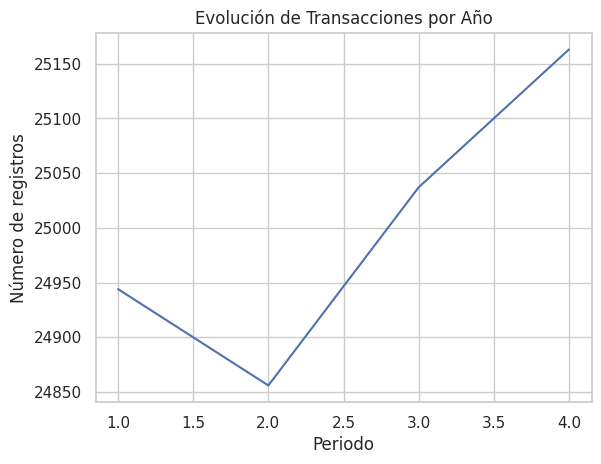

In [ ]:
## Gráfico evolución de transacciones (Año)
trans_anio.plot(
    kind="line",
    title="Evolución de Transacciones por Año",
    xlabel="Periodo",
    ylabel="Número de registros"
)

<Axes: title={'center': 'Evolución de Transacciones por Año-Trimestre'}, xlabel='Periodo', ylabel='Número de registros'>

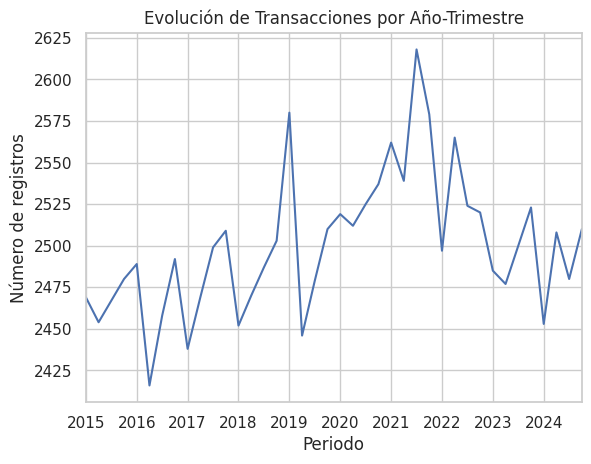

In [ ]:
## Gráfico evolución de transacciones (Año-Trimestre)
trans_anio_trim.plot(
    kind="line",
    title="Evolución de Transacciones por Año-Trimestre",
    xlabel="Periodo",
    ylabel="Número de registros"
)

##### 🧠 Interpretación de resultados

Se observa un patrón bastante recurrente en el que el número de transacciones cae durante el primer trimestre respecto al cierre del año anterior y aumenta progresivamente durante los siguientes trimestres, alcanzando normalmente valores altos en el tercer trimestre. Este comportamiento se vuelve más irregular en los últimos años. El máximo se alcanza en 2021 y el mínimo en 2016.

##### 🤖 Recomendación IA

**Prompt: Cómo puedo mejorar la visualización de la evolución del número de transacciones a lo largo del tiempo solo utilizando la libreria pandas?**

Para mejorar la visualización de la evolución de las transacciones utilizando únicamente la librería pandas, podemos aprovechar los argumentos avanzados del método `.plot()`.

**Prompt: Aceptar y ejecutar**

Podemos convertir el índice a tipo datetime directamente sobre la serie antes de graficar para que pandas gestione el eje temporal de forma continua y limpia. Además, utilizaremos parámetros nativos de pandas como marker para los puntos, grid para la cuadrícula, y figsize para dar un aspecto más profesional sin importar librerías externas.

¡Excelente! El gráfico se ha generado correctamente utilizando únicamente la API de pandas.

<Axes: title={'center': 'Evolució Històrica de Transaccions (Detall Trimestral - Només amb Pandas)'}, xlabel='Eix Temporal', ylabel='Nombre de Transaccions'>

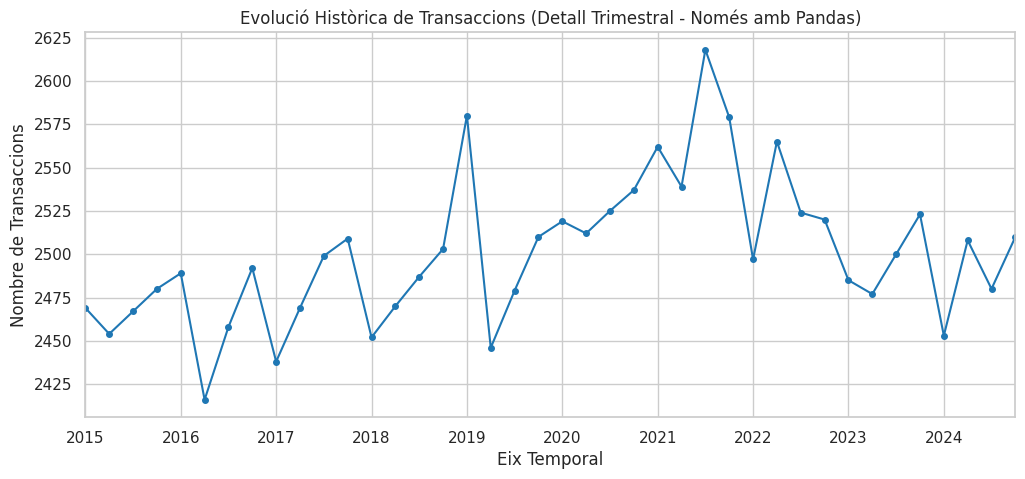

In [ ]:
# Copiamos la serie y convertimos el PeriodIndex a Timestamp para que pandas gestione el tiempo correctamente
trans_pandas_dt = trans_anio_trim.copy()
trans_pandas_dt.index = trans_pandas_dt.index.to_timestamp()

# Creamos el gráfico mejorado utilizando exclusivamente la API de pandas
trans_pandas_dt.plot(
    kind="line",
    figsize=(12, 5),
    marker="o",
    markersize=4,
    color="#1f77b4",
    grid=True,
    title="Evolució Històrica de Transaccions (Detall Trimestral - Només amb Pandas)",
    xlabel="Eix Temporal",
    ylabel="Nombre de Transaccions"
)

##### 🧐 Comparación critica

Es evidente el nivel de detalle y profesionalidad que ha aportado la IA al resultado final con un prompt básico sin muchos detalles ni contexto.

Mis conocimientos actuales me permiten entender cómo llegar a un resultado básico, haciendo las transformaciones necesarias sobre los datos y analizando qué información mostrar para entender, en este caso, una evolución temporal. Sin embargo, el uso de la IA ha permitido pulir de manera considerable el resultado, pasando de un gráfico que, aunque mostraba una evolución temporal comprensible, no permitía visualizar de forma tan precisa los periodos del eje X (año + trimestre), a un gráfico mucho más claro, con marcadores definidos y una presentación visual más profesional y potente.

También considero importante destacar que mis conocimientos previos me permiten entender exactamente qué cambios ha realizado la IA y por qué, además de poder valorar si el resultado es correcto o necesita modificaciones adicionales. En este caso, considero que el resultado final no requiere más ajustes.

#### ⚡2. Usuarios con más volumen de facturación

##### 💻 Código inicial

In [ ]:
## Comprobación de datos
tipo = transacciones["user_id"].dtype
null_id = transacciones["user_id"].isna().sum()

display(tipo, null_id)

dtype('int64')

np.int64(0)

In [ ]:
## Filtrar transacciones
ventas = transacciones[transacciones['declined'] == 0]
ventas.head()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018-12-12 08:05:17,176.45,0,"75, 73, 98",2313,59.620510,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018-11-04 23:16:18,548.77,0,"92, 85, 36, 23",3834,39.224213,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46


In [ ]:
## Agrupar y ordenar total de ventas por usuario
ventas_usuario = (transacciones.groupby("user_id")["amount"].sum().sort_values(ascending=False))
ventas_usuario.head(15)

,amount
user_id,
289,47332.90
318,47133.55
455,41396.68
417,37393.91
185,34576.49
285,33383.56
454,29528.42
349,27835.38
193,27462.59


In [ ]:
## Convertir Serie a DF y seleccionar top 15
ventas_usuario_df = pd.DataFrame(ventas_usuario.head(15))
ventas_usuario_df = ventas_usuario_df.reset_index()
ventas_usuario_df.head()

,user_id,amount
0,289,47332.90
1,318,47133.55
2,455,41396.68
3,417,37393.91
4,185,34576.49


Text(0.5, 1.0, 'Usuarios con mayor volumen de facturación')

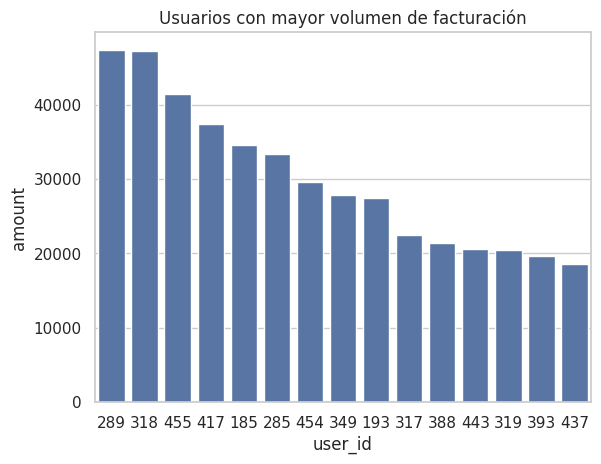

In [ ]:
## Crear gráfico "Usuarios con mayor volumen de facturación"
import seaborn as sns

sns.set_theme(style="whitegrid")
orden = ventas_usuario_df["user_id"]

grafico = sns.barplot(data=ventas_usuario_df, x="user_id", y="amount", order=orden)

grafico.set_title("Usuarios con mayor volumen de facturación")

##### 🧠 Interpretación de resultados

Dentro del top 15, los usuarios 289 y 318 destacan claramente con un volumen de facturación cercano a los 47.000, mientras que a partir del tercer usuario se observa una bajada más marcada. El usuario 437 cierra el ranking con un volumen aproximado de 18.500.

##### 🤖 Recomendación IA

**Prompt: Mejora el gráfico "Usuarios con mayor volumen de facturación". Usa solo la libraría seaborn y que el gráfico sea de barras con los datos ordenados de forma descendente**

He millorat el gràfic de barres utilitzant exclusivament la llibreria seaborn, ordenant les dades de manera descendent amb una paleta de colors professional, un format d'eix millorat, un disseny net i un títol clar.

**Prompt: Aceptar y ejecutar**

Perfecte! Hem aplicat amb èxit la millora al gràfic "Top 15 Usuaris amb Major Volum de Facturació".

Com pots veure, ara el gràfic s'ha generat utilitzant exclusivament seaborn i matplotlib de forma altament professional:

S'ha establert un ordre descendent rigorós basant-nos en el volum de facturació.
Hem utilitzat una paleta de colors coherent `(Blues_r)`.
S'han millorat les etiquetes de l'eix X `(user_id)`, de l'eix Y `(amount)` i el títol de manera neta i visible.

**Prompt: Corrige el código, solo puedes usar la libreria de seaborn y pandas**

He corregit el codi de la cel·la per utilitzar estrictament les llibreries pandas i seaborn, eliminant qualsevol referència directa a `matplotlib.pyplot` de l'script.

He revisat el codi i confirmo que és correcte. Ara s'ajusta perfectament als teus requisits: utilitza exclusivament les llibreries pandas (per processar la llista d'ordenació) i seaborn (per configurar completament l'estil visual, l'estructura de barres i afegir les etiquetes i el títol directament sobre l'objecte d'eixos). S'ha eliminat completament qualsevol importació o ús directe de matplotlib.

Text(0, 0.5, 'Volum Total Facturat (amount)')

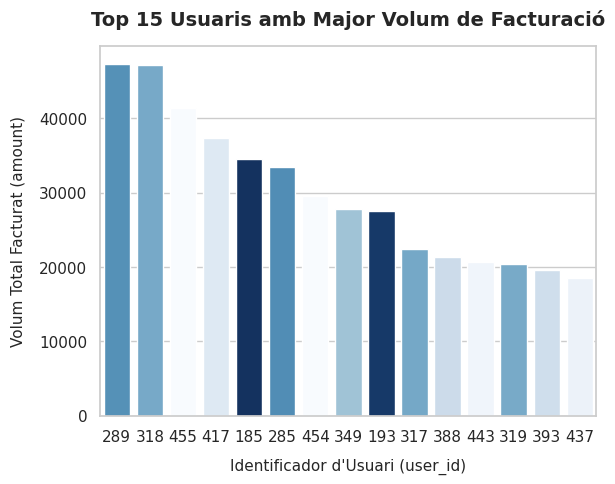

In [ ]:
## Generar gráfico "Usuarios con mayor volumen de facturación" mejorado (Solo Seaborn y Pandas)
import pandas as pd
import seaborn as sns

# Configurar el tema visual nativo de seaborn
sns.set_theme(style="whitegrid")

# Crear el listado ordenado de IDs utilizando pandas
orden_ids = ventas_usuario_df["user_id"].tolist()

# Crear gráfico de barras utilizando únicamente seaborn
grafico_3 = sns.barplot(
    data=ventas_usuario_df,
    x="user_id",
    y="amount",
    order=orden_ids,
    palette="Blues_r",
    hue="user_id",
    legend=False
)

# Añadir título y etiquetas directamente mediante el objeto del eje de seaborn
grafico_3.set_title("Top 15 Usuaris amb Major Volum de Facturació", fontsize=14, pad=15, fontweight='bold')
grafico_3.set_xlabel("Identificador d'Usuari (user_id)", fontsize=11, labelpad=10)
grafico_3.set_ylabel("Volum Total Facturat (amount)", fontsize=11, labelpad=10)

##### 🧐 Comparación critica

En este caso, la IA necesitó algunas correcciones. Si bien es cierto que el prompt inicial era bastante escueto, se indicaba de forma explícita que debía utilizarse únicamente la librería Seaborn. En su primera ejecución, la IA incorporó código de Matplotlib, por lo que fue necesario corregir este primer resultado para ajustarlo correctamente a las instrucciones.

Más allá de esta situación puntual, es evidente que la IA ha mejorado de forma considerable el resultado final. Sin embargo, la diferencia es menos marcada que en el ejercicio anterior y, en este caso, la mejora se centra principalmente en aspectos de formato y presentación, como el uso de colores, espacios, títulos y una mejor organización visual del gráfico.

Otro punto a destacar es el problema con el idioma. A pesar de que las interacciones se realizaron en español, probablemente debido a que el enunciado original del ejercicio está en catalán, la IA respondió y propuso los resultados en catalán. Esto demuestra que, aunque el resultado técnico puede ser correcto, sigue siendo necesario revisar aspectos de contexto y formato para asegurar que la respuesta se ajuste exactamente a lo solicitado.

#### ⚡3. Análisis de transacciones (hora y estado)

##### 💻 Código inicial

In [ ]:
## Creacion de DF "resumen"
resumen = transacciones[["id", "user_id", "timestamp", "amount", "declined"]].copy()

resumen = resumen.rename(columns={"declined": "status"})

resumen["status"] = resumen["status"].replace({
    0: "Admitted",
    1: "Declined"
})

resumen["hour"] = resumen["timestamp"].dt.hour

resumen.head()

,id,user_id,timestamp,amount,status,hour
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,2313,2018-12-12 08:05:17,176.45,Admitted,8
1,09456357-8E9B-475A-8257-87A023699964,554,2024-05-20 22:49:08,206.65,Admitted,22
2,C47C7C84-C174-4973-A76B-825A9DB5582A,3834,2018-11-04 23:16:18,548.77,Admitted,23
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,1972,2022-06-17 09:17:25,411.55,Admitted,9
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,3097,2020-11-29 07:29:16,410.65,Admitted,7


Text(0.5, 1.0, 'Análisis de transacciones hora/estado')

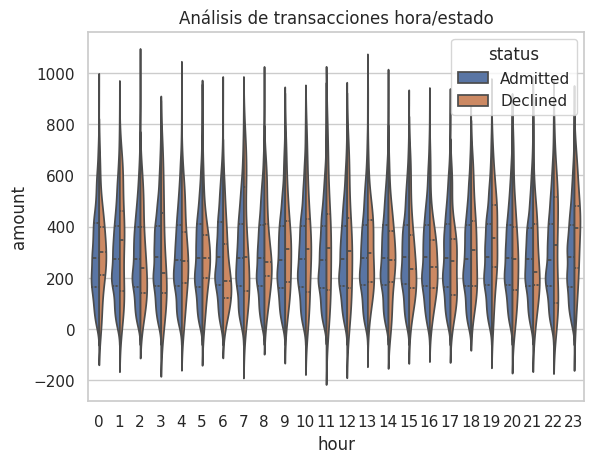

In [ ]:
## Creación de gráfico
grafico_4 = sns.violinplot(
    data=resumen,
    x="hour",
    y="amount",
    hue="status",
    split=True,
    inner="quartile"
)

grafico_4.set_title("Análisis de transacciones hora/estado")

##### 🧠 Interpretación de resultados

La distribución de los importes es bastante similar durante todas las horas del día. Tampoco se observan diferencias importantes entre las transacciones aceptadas y rechazadas, ya que tanto la concentración de los importes como sus medianas y cuartiles presentan valores muy similares.

##### 🤖 Recomendación IA

**Prompt: Crea una versión alternativa del grafico "Análisis de transacciones hora/estado". Manten los mismos parametros del gráfico original y no inventes ningún dato.**

He creado una versión alternativa y mejorada del gráfico de violín "Análisis de transacciones hora/estado". Esta versión optimiza los colores, mejora el grosor de las líneas y estiliza las etiquetas de los ejes para que el resultado sea mucho más profesional, manteniendo exactamente todos tus parámetros de configuración y los datos originales del DataFrame `resumen`.

**Prompt: Aceptar y ejecutar**

¡Listo! He comprobado los resultados de la ejecución de la celda 91de232f. El gráfico alternativo de violín ("Análisis de transacciones hora/estado") se ha generado correctamente utilizando únicamente `seaborn` y `pandas`. Los parámetros originales se mantienen intactos, respetando los datos reales del DataFrame `resumen` sin ninguna alteración.

Text(0, 0.5, 'Importe de la Transacción')

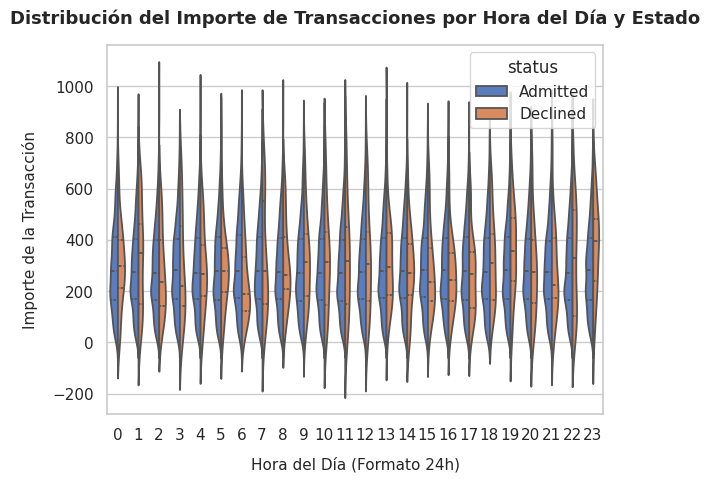

In [ ]:
## Versión alternativa mejorada: Análisis de transacciones hora/estado
import seaborn as sns

# Ajustar el estilo y fondo visual con seaborn
sns.set_theme(style="whitegrid")

# Crear el violinplot optimizado con los parámetros requeridos
grafico_4_alt = sns.violinplot(
    data=resumen,
    x="hour",
    y="amount",
    hue="status",
    split=True,
    inner="quartile",
    palette="muted",
    linewidth=1.3
)

# Personalizar etiquetas y título usando la API del objeto Axes
grafico_4_alt.set_title("Distribución del Importe de Transacciones por Hora del Día y Estado", fontsize=13, pad=15, fontweight='bold')
grafico_4_alt.set_xlabel("Hora del Día (Formato 24h)", fontsize=11, labelpad=10)
grafico_4_alt.set_ylabel("Importe de la Transacción", fontsize=11, labelpad=10)

##### 🧐 Comparación critica

En este caso, la diferencia entre el gráfico original y la propuesta de la IA es mínima. A diferencia de los ejercicios anteriores, el prompt no solicitaba mejorar el gráfico existente, sino crear una versión alternativa, lo que probablemente explica que los cambios se limitaran principalmente a aspectos de presentación.

Las modificaciones se centraron en elementos visuales como títulos, uso de negritas y pequeños ajustes de formato. La aportación de la IA fue mucho menos significativa que en los ejercicios anteriores y vale destacar que el gráfico original ya respondía correctamente a la pregunta planteada y permitía comparar la distribución de los importes según la hora y el estado de la transacción, por lo que la versión alternativa se limitó principalmente a cambios estéticos sin aportar mejoras relevantes a nivel analítico.

#### ⚡ 4. Días de mayor actividad en ventas

##### 💻 Código inicial

In [ ]:
## Creacion de DF "dias_semana"
dias_semana = transacciones[["id", "user_id", "timestamp", "amount", "declined"]].copy()

dias_semana = dias_semana[dias_semana['declined'] == 0]

dias_semana["week_day"] = dias_semana["timestamp"].dt.dayofweek

dias_semana["week_day"] = dias_semana["week_day"].replace({
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
})

dias_semana.head()

,id,user_id,timestamp,amount,declined,week_day
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,2313,2018-12-12 08:05:17,176.45,0,Wednesday
1,09456357-8E9B-475A-8257-87A023699964,554,2024-05-20 22:49:08,206.65,0,Monday
2,C47C7C84-C174-4973-A76B-825A9DB5582A,3834,2018-11-04 23:16:18,548.77,0,Sunday
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,1972,2022-06-17 09:17:25,411.55,0,Friday
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,3097,2020-11-29 07:29:16,410.65,0,Sunday


Text(0.5, 1.0, 'Análisis de ventas por día de la semana')

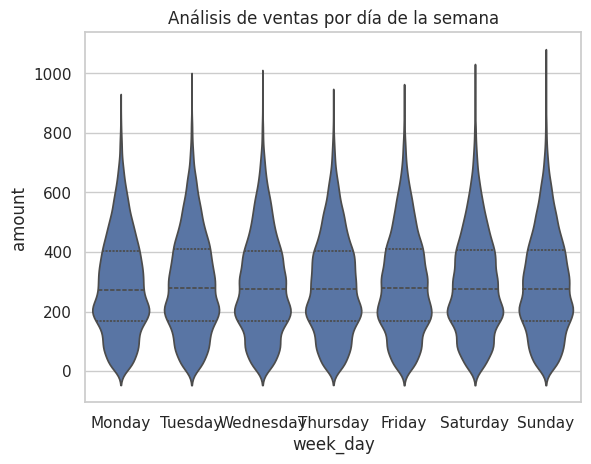

In [ ]:
## Crear gráfico

orden_dias = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

grafico_5 = sns.violinplot(
    data=dias_semana,
    x="week_day",
    y="amount",
    inner="quartile",
    order=orden_dias
)

grafico_5.set_title("Análisis de ventas por día de la semana")

##### 🧠 Interpretación de resultados

La distribución de los importes de las ventas es muy similar durante todos los días de la semana. Las medianas y los cuartiles se mantienen prácticamente estables, por lo que no se observa un día con un comportamiento claramente diferente al resto.

##### 🤖 Propuesta IA

**Prompt: En una celda nueva, mejora el grafico "Análisis de ventas por día de la semana". El objetivo es mostrar con un violinplot la distribución de las ventas por los días de la semana. No inventes datos.**

He creado una celda nueva inmediatamente después del gráfico de violín original de días de la semana. En esta versión alternativa y mejorada, optimizamos la visualización aplicando una paleta de colores coherente, refinando las líneas y estilizando los títulos y las etiquetas de los ejes de forma limpia y profesional con `seaborn` y `pandas`.

<br>

**Prompt: Aceptar y ejecutar**

¡Excelente! La versión mejorada del gráfico "Análisis de ventas por día de la semana" se ha generado y ejecutado correctamente en la celda nueva (e48cd036).

<br>

**Mejoras aplicadas en esta versión**:

**Estilo profesional**: Se ha implementado el tema whitegrid de Seaborn para mayor claridad.

**Paleta de colores elegante**: Se aplicó la paleta "Blues" que distribuye gradualmente las tonalidades de menor a mayor intensidad a lo largo de los días de la semana.

**Acabado y formato**: Se incrementó el grosor de las líneas (linewidth=1.3) para delimitar mejor la silueta de los violines y se añadieron títulos y etiquetas estilizadas con mejor espaciado (pad y labelpad) y tamaños de fuente más profesionales.

**Nota**: La advertencia que se muestra en la salida es un aviso preventivo de futuras versiones de Seaborn sobre el uso de palette sin asignar la variable hue, pero no afecta en absoluto a la visualización actual de tu gráfico.

/tmp/ipykernel_2636/3269246409.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  grafico_5_mejorado = sns.violinplot(


Text(0, 0.5, 'Importe de las Ventas (amount)')

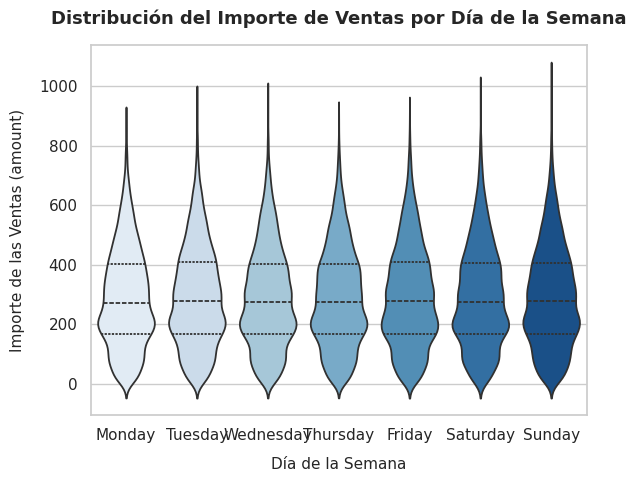

In [ ]:
## Versión alternativa mejorada: Análisis de ventas por día de la semana
import seaborn as sns

# Configurar el estilo visual de seaborn
sns.set_theme(style="whitegrid")

# Mantener el orden específico de los días de la semana
orden_dias = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

# Generar el gráfico de violín mejorado con los datos y parámetros requeridos
grafico_5_mejorado = sns.violinplot(
    data=dias_semana,
    x="week_day",
    y="amount",
    inner="quartile",
    order=orden_dias,
    palette="Blues",
    linewidth=1.3
)

# Añadir un título y etiquetas profesionales directamente usando el objeto Axes
grafico_5_mejorado.set_title("Distribución del Importe de Ventas por Día de la Semana", fontsize=13, pad=15, fontweight='bold')
grafico_5_mejorado.set_xlabel("Día de la Semana", fontsize=11, labelpad=10)
grafico_5_mejorado.set_ylabel("Importe de las Ventas (amount)", fontsize=11, labelpad=10)

##### 🧐 Comparación critica

En este caso, la diferencia entre el gráfico original y la propuesta de la IA es mínima. A diferencia de los ejercicios anteriores, el prompt no solicitaba mejorar el gráfico existente, sino crear una versión alternativa, lo que probablemente explica que los cambios se limitaran principalmente a aspectos de presentación.

Las modificaciones se centraron en elementos visuales como títulos, uso de negritas y pequeños ajustes de formato. La aportación de la IA fue mucho menos significativa que en los ejercicios anteriores y vale destacar que el gráfico original ya respondía correctamente a la pregunta planteada y permitía comparar la distribución de los importes según la hora y el estado de la transacción, por lo que la versión alternativa se limitó principalmente a cambios estéticos sin aportar mejoras relevantes a nivel analítico.

## **Exercici 2**: Preguntes analítiques complexes (amb guia)

### 🚩 Problema planteado

🌍 **Context**: Aquest exercici requereix combinar informació de diverses taules del model per poder respondre correctament les preguntes.

<br>

Aquí sí que serà necessari:
*   Fer merge entre taules.
*   Utilitzar groupby, pivot_table, crosstab...
*   Aplicar agregacions, transformacions intermèdies i funcions.

<br>

**Preguntes analítiques** (amb guia general)

*   Depenem excessivament d'un nombre reduït de països de companyies venedores?

Passos orientatius:

1. Combinar la informació de transaccions amb la de companyies.
2. Agrupar la facturació per país.
3. Calcular la facturació total generada per cada país.
4. Ordenar els països de major a menor facturació.
5. Calcular el percentatge acumulat sobre el total.
6. Visualitzar.

*   Existeix estacionalitat en les vendes?

Passos orientatius:

1. Treballar amb dates de transacció.
2. Extreure la informació temporal rellevant (any i mes).
3. Calcular el volum total de vendes (suma de amount) per any i mes.
4. Comparar patrons temporals amb la comparació entre anys. Crea una taula tipus pivot.
5. Visualitzar l'evolució.

*   Anàlisi de concentració i variabilitat (tria UNA opció)

    *   **Opció A – Producte** (Només si disposes de la taula de productes)

Quins productes generen més ingressos i amb quina variabilitat?

Passos orientatius:

1. Combinar transaccions, la taula pont i productes.
2. Calcular ingressos per producte amb un groupby, sum y sort.
3. Selecciona els top N productes: 15 per exemple.
4. Escollir una visualització adequada per analitzar dispersió.

    *   **Opció B – Activitat d'usuaris** (Alternativa si no disposes de la taula de productes)

Hi ha usuaris que han deixat de comprar recentment?

Passos orientatius:

1. Identificar l'última compra per usuari.
2. Calcular el temps des de l'última compra.
3. Visualitzar la distribució del temps des de l'última compra.

*   Com varia l'activitat de venda per franges horàries al llarg dels anys? (patrons horaris)

Passos orientatius:

1. Crear franges horàries a partir de l'hora: crea una funció i aplica-la utilitzant apply.
2. Construir una taula agregada utilitzant crosstab.
3. Visualitzar amb un heatmap.

<br>

👉 **Per a cada pregunta**:

*   Descriu breument els passos seguits.
*   Mostra la visualització final.
*   Interpreta què implica per al negoci.

### 🧩 Desarrollo paso a paso

#### ⚡ Cargar e inspeccionar tablas

In [ ]:
## Cargar "companies" y "transactions" N2-Ex.8
import pandas as pd

transacciones = pd.read_csv("/content/N2-Ex.8_transactions.csv", sep=";")
companias = pd.read_csv("/content/N2-Ex.8_companies.csv", sep=";")

In [ ]:
## Comprobar datos "companias"
companias.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   company_id               100 non-null    object
 1   company_name             100 non-null    object
 2   phone                    100 non-null    object
 3   email                    100 non-null    object
 4   country                  100 non-null    object
 5   website                  100 non-null    object
 6   merchant_category        100 non-null    object
 7   merchant_price_position  100 non-null    object
dtypes: object(8)
memory usage: 6.4+ KB


In [ ]:
## Comprobar datos "transacciones"
transacciones.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                100000 non-null  object 
 1   card_id           100000 non-null  object 
 2   business_id       100000 non-null  object 
 3   timestamp         100000 non-null  object 
 4   amount            100000 non-null  float64
 5   declined          100000 non-null  int64  
 6   product_ids       100000 non-null  object 
 7   user_id           100000 non-null  int64  
 8   lat               100000 non-null  float64
 9   longitude         100000 non-null  float64
 10  discount_amount   100000 non-null  float64
 11  tax_amount        100000 non-null  float64
 12  shipping_amount   100000 non-null  float64
 13  channel           100000 non-null  object 
 14  campaign_id       100000 non-null  object 
 15  device_type       100000 non-null  object 
 16  is_international  100

#### ⚡ 1. Dependencia de píases

##### 💻 Código inicial

In [ ]:
## Merge "transacciones" y "companias"
trans_company = pd.merge(
    transacciones,
    companias,
    left_on="business_id",
    right_on="company_id",
    how="left"
)

trans_company.head()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,decline_reason,distance_km,company_id,company_name,phone,email,country,website,merchant_category,merchant_price_position
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018-12-12 08:05:17,176.45,0,"75, 73, 98",2313,59.620510,16.559977,...,NaN,129.25,b-2466,Amet Lorem LLP,+40 468 847 7738,ultricies.adipiscing@icloud.edu,Spain,https://www.amet-lorem-llp.com,Toys,mid-market
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,...,NaN,0.57,b-2342,Fringilla Porttitor Incorporated,+81 232 896 8043,ultrices.a.auctor@protonmail.couk,Sweden,https://www.fringilla-porttitor-incorporated.com,Electronics,mid-market
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018-11-04 23:16:18,548.77,0,"92, 85, 36, 23",3834,39.224213,-0.288066,...,NaN,1498.24,b-2250,Amet Nulla Donec Corporation,+96 338 276 8449,mattis.integer.eu@protonmail.net,Italy,https://www.amet-nulla-donec-corporation.com,Gaming,budget
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,...,NaN,0.68,b-2610,Egestas Nunc Sed Limited,+39 297 745 2202,vitae@hotmail.edu,Italy,https://www.egestas-nunc-sed-limited.com,Books,budget
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,...,NaN,78.46,b-2454,Justo Eu Arcu Ltd,+68 493 166 1232,ac.facilisis@icloud.couk,Italy,https://www.justo-eu-arcu-ltd.com,Travel,mid-market


In [ ]:
## Facturacion total cada país
filtro_ventas = trans_company[trans_company['declined'] == 0]
facturacion_pais = filtro_ventas.groupby('country')[['amount']].sum()

facturacion_pais.head()

,amount
country,
Australia,687532.20
Belgium,937789.26
Canada,552067.53
China,235421.76
France,1406668.15


In [ ]:
## Ordenar y calcular porcentajes
facturacion_pais = facturacion_pais.reset_index()
facturacion_porcentajes = facturacion_pais.sort_values("amount", ascending=False)

facturacion_porcentajes["porcentaje"] = (
    facturacion_porcentajes["amount"] / facturacion_porcentajes["amount"].sum() * 100
)

facturacion_porcentajes["porcentaje_acumulado"] = facturacion_porcentajes["porcentaje"].cumsum()

facturacion_porcentajes[["porcentaje", "porcentaje_acumulado"]] = (
    facturacion_porcentajes[["porcentaje", "porcentaje_acumulado"]].round(2)
)

display(facturacion_porcentajes)

,country,amount,porcentaje,porcentaje_acumulado
12,Sweden,4884250.39,16.83,16.83
8,Netherlands,4470873.59,15.40,32.23
13,United Kingdom,4065098.37,14.01,46.24
7,Italy,4061060.93,13.99,60.23
5,Germany,3984664.03,13.73,73.96
4,France,1406668.15,4.85,78.80
14,United States,1085266.88,3.74,82.54
1,Belgium,937789.26,3.23,85.77
10,Norway,798331.87,2.75,88.52
6,Ireland,707379.30,2.44,90.96


##### 📈 Visualización

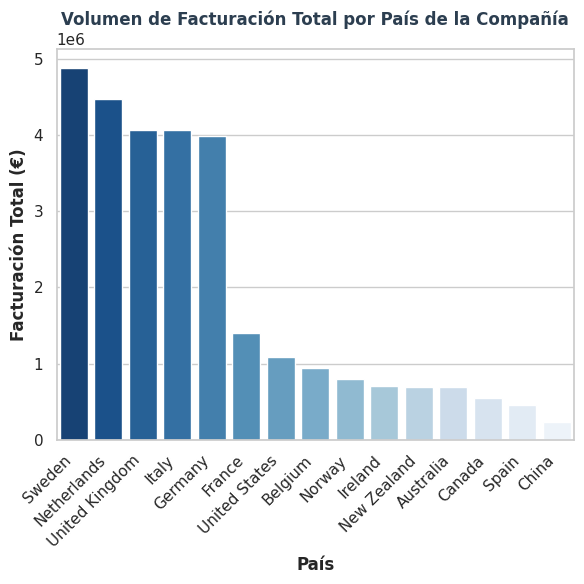

In [ ]:
## Creación de gráfico de barras monto_facturacion/país
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 6))

grafico_fp = sns.barplot(
    data=facturacion_porcentajes,
    x="country",
    y="amount",
    palette="Blues_r",
    hue="country",
    legend=False
)

plt.xticks(rotation=45, ha="right")

grafico_fp.set_title("Volumen de Facturación Total por País de la Compañía",
                     fontweight='bold', color='#2c3e50')
grafico_fp.set_ylabel("Facturación Total (€)",
                      fontweight='semibold')
grafico_fp.set_xlabel("País",
                      fontweight='semibold')

plt.tight_layout()
plt.show()


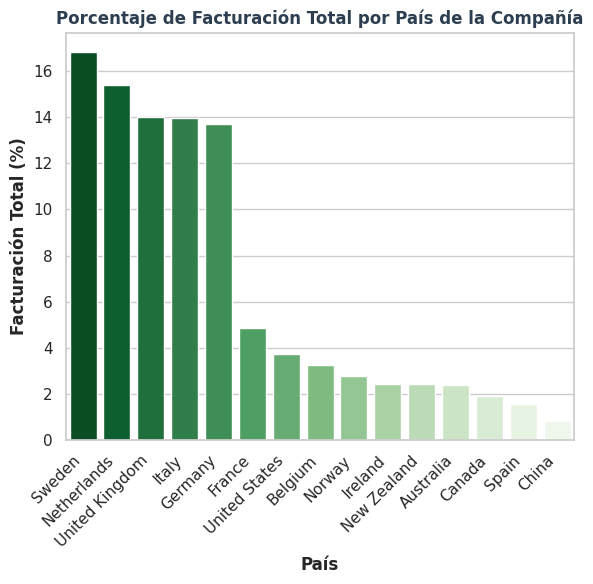

In [ ]:
## Creación de gráfico de barras porcentaje_facturacion/país
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 6))

grafico_pp = sns.barplot(
    data=facturacion_porcentajes,
    x="country",
    y="porcentaje",
    palette="Greens_r",
    hue="country",
    legend=False
)

plt.xticks(rotation=45, ha="right")

grafico_pp.set_title("Porcentaje de Facturación Total por País de la Compañía",
                     fontweight='bold', color='#2c3e50')
grafico_pp.set_ylabel("Facturación Total (%)",
                      fontweight='semibold')
grafico_pp.set_xlabel("País",
                      fontweight='semibold')

plt.tight_layout()
plt.show()

##### 💡 Análisis de resultados

*   No existe dependencia de un único país, pero sí una concentración clara de la facturación en un grupo reducido de cinco países europeos. Estos países representan aproximadamente 74% de la facturación total.

*   A partir de Francia se observa una caída considerable, pasando de países que representan aproximadamente entre el 14% y el 16% de la facturación, a países que no ocupan más del 5%.

*   Suecia es el pais con mayor facturación y China el menor, representando el 16.83% y el 0,81% respectivamente.

*   Esta concentración supone que, aunque no existe dependencia de un único mercado, una parte importante de **la facturación está expuesta al comportamiento de un grupo reducido de países**.

#### ⚡ 2. Estacionalidad de las ventas

##### 💻 Código inicial

In [ ]:
## Crear filtro con transacciones aceptadas
ventas_confirmadas = transacciones[transacciones["declined"] == 0].copy()

In [ ]:
## Extraer "año" y "mes"
ventas_confirmadas["timestamp"] = pd.to_datetime(ventas_confirmadas["timestamp"])

ventas_confirmadas["anio"] = ventas_confirmadas["timestamp"].dt.year
ventas_confirmadas["mes"] = ventas_confirmadas["timestamp"].dt.month

In [ ]:
## Agrupar y calcular total de ventas
ventas_acumuladas = ventas_confirmadas.groupby(['anio', 'mes'])[['amount']].sum()
ventas_acumuladas.head()

amount
anio mes           
2015 1    221978.21
     2    245780.13
     3    253000.65
     4    245597.21
     5    248585.36

In [ ]:
## Generación de Pivot Table
pivot_ventas = ventas_acumuladas.pivot_table(
    index="mes",
    columns="anio",
    values="amount",
    aggfunc="sum"
)

pivot_ventas

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mes,,,,,,,,,,
1,221978.21,224451.27,222956.21,227411.90,222944.11,231702.95,243339.85,224709.53,228413.66,226393.73
2,245780.13,248112.42,252303.71,245092.09,259807.32,248318.04,257434.31,235427.85,251422.67,249898.07
3,253000.65,246634.37,237621.09,237099.83,276818.21,258872.56,250861.14,271978.12,241711.00,245792.02
4,245597.21,240833.04,251596.72,234246.30,242707.81,244251.90,259770.51,237165.49,241264.06,244769.15
5,248585.36,241306.84,240125.80,244448.97,242550.42,253699.74,239662.08,276262.60,261355.45,254122.62
6,232624.35,230577.43,240337.61,242769.22,241694.85,236410.96,234080.71,260082.37,232254.56,244370.81
7,241252.27,237081.73,240576.35,231261.73,233513.25,240255.64,251450.91,233349.01,238652.72,230031.53
8,233797.97,235600.88,230225.76,228759.89,237070.53,232658.86,237051.75,245198.95,237981.15,236671.63
9,227211.93,241530.84,230606.28,236768.38,232551.83,257964.96,245398.37,254316.72,234226.30,234226.89


##### 📈 Visualización

Text(0, 0.5, 'Facturación (€)')

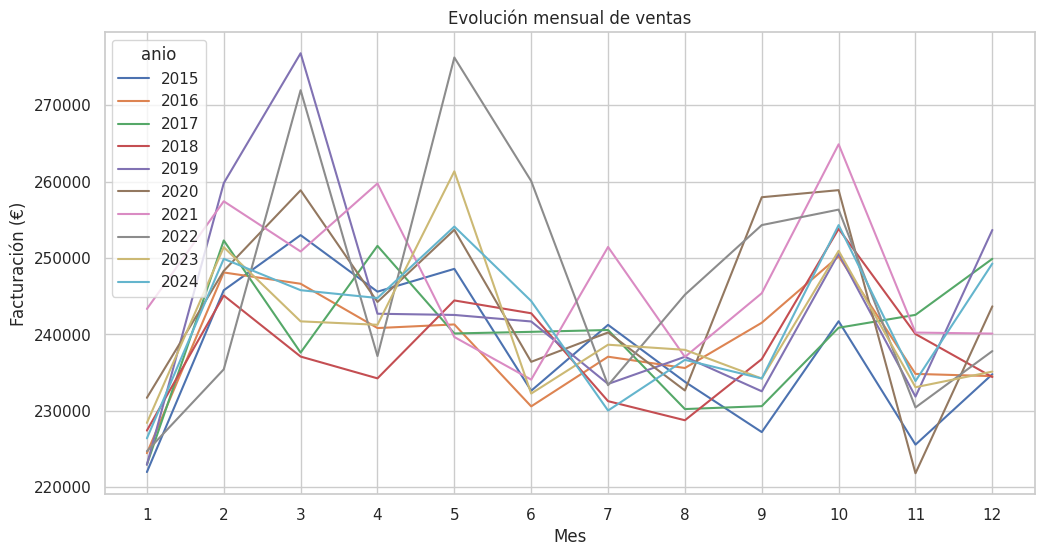

In [ ]:
## Generación de gráfico de linea temporal por año
ventas_acumuladas_g = pivot_ventas.plot(kind="line", figsize=(12, 6))
ventas_acumuladas_g.set_xticks(range(1, 13))

ventas_acumuladas_g.set_title("Evolución mensual de ventas")
ventas_acumuladas_g.set_xlabel("Mes")
ventas_acumuladas_g.set_ylabel("Facturación (€)")

##### 💡 Análisis de resultados

*   No se observa una estacionalidad clara en las ventas, ya que los principales picos se producen en distintos meses según el año.

*   2019, 2022 y 2021 presentan los valores más altos, pero estos ocurren en marzo, mayo y octubre respectivamente.  

*   Febrero y octubre destacan como meses en los que se observa un aumento de las ventas de forma bastante constante entre años, aunque con diferente intensidad. Esto podría indicar cierto patrón estacional en estos meses, pero no lo suficientemente fuerte como para hablar de una estacionalidad general clara.

*   Para el negocio, esto implica que todavía no hay un patrón estacional suficientemente claro como para basar toda la estrategia comercial en meses concretos. Sin embargo, febrero y octubre muestran incrementos recurrentes, por lo que convendría analizar qué factores coinciden con esos periodos. Si existe algún evento, campaña o comportamiento de consumo asociado, los meses previos podrían ser un buen momento para reforzar acciones comerciales y promocionales.

#### ⚡ 3. Productos destacados (Opción A)

##### 💻 Código inicial

In [ ]:
## Cargar "products" y "trans_products" N2-Ex.8
productos = pd.read_csv("/content/N2-Ex.8_products.csv", sep=";")
tabla_puente = pd.read_csv("/content/N2-Ex.8_trans_products.csv", sep=";")

In [ ]:
## Inspección general transacciones"
transacciones.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                100000 non-null  object 
 1   card_id           100000 non-null  object 
 2   business_id       100000 non-null  object 
 3   timestamp         100000 non-null  object 
 4   amount            100000 non-null  float64
 5   declined          100000 non-null  int64  
 6   product_ids       100000 non-null  object 
 7   user_id           100000 non-null  int64  
 8   lat               100000 non-null  float64
 9   longitude         100000 non-null  float64
 10  discount_amount   100000 non-null  float64
 11  tax_amount        100000 non-null  float64
 12  shipping_amount   100000 non-null  float64
 13  channel           100000 non-null  object 
 14  campaign_id       100000 non-null  object 
 15  device_type       100000 non-null  object 
 16  is_international  100

In [ ]:
## Inspección general "productos"
productos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            100 non-null    int64  
 1   product_name  100 non-null    object 
 2   price         100 non-null    object 
 3   colour        100 non-null    object 
 4   weight        100 non-null    float64
 5   warehouse_id  100 non-null    object 
 6   category      100 non-null    object 
 7   brand         100 non-null    object 
 8   cost          100 non-null    object 
 9   launch_date   100 non-null    object 
dtypes: float64(1), int64(1), object(8)
memory usage: 7.9+ KB


In [ ]:
## Inspección general "tabla_puente"
tabla_puente.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129767 entries, 0 to 129766
Data columns (total 2 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   transaction_id  129767 non-null  object
 1   product_id      129767 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 2.0+ MB


In [ ]:
## Modificaciones previo merge
transacciones = transacciones.rename(columns={"id": "transaction_id"})
productos = productos.rename(columns={"id": "product_id"})

In [ ]:
## Merge transacciones con prouctos
trans_completa = (
    transacciones
    .merge(tabla_puente, left_on="transaction_id", right_on="transaction_id")
    .merge(productos, on="product_id")
)

trans_completa.head()

,transaction_id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,product_id,product_name,price,colour,weight,warehouse_id,category,brand,cost,launch_date
0,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,...,3,duel tourney Lannister,$171.13,#d8d8d8,1.5,WH-2,Food,Daily Pantry,$107.07,2013-08-18
1,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,...,5,skywalker ewok,$171.22,#dbdbdb,3.2,WH-0,Home,NordHaus,$83.69,2014-07-17
2,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,...,27,Stannis riverlands,$172.93,#7a7a7a,1.5,WH-22,Home,NordHaus,$83.83,2014-01-08
3,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,...,38,ewok sith,$55.43,#666666,2.0,WH-33,Electronics,Nexa,$36.05,2014-12-01
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,...,32,north,$178.28,#0f0f0f,1.4,WH-27,Home,CasaNova,$98.47,2013-12-15


In [ ]:
## Conversión datos numericos
trans_completa = trans_completa.copy()

trans_completa["price"] = trans_completa["price"].astype(str)

trans_completa["price"] = (
    trans_completa["price"]
    .str.replace("$", "", regex=False)
)

trans_completa["price"] = pd.to_numeric(trans_completa["price"])

trans_completa.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129767 entries, 0 to 129766
Data columns (total 29 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    129767 non-null  object 
 1   card_id           129767 non-null  object 
 2   business_id       129767 non-null  object 
 3   timestamp         129767 non-null  object 
 4   amount            129767 non-null  float64
 5   declined          129767 non-null  int64  
 6   product_ids       129767 non-null  object 
 7   user_id           129767 non-null  int64  
 8   lat               129767 non-null  float64
 9   longitude         129767 non-null  float64
 10  discount_amount   129767 non-null  float64
 11  tax_amount        129767 non-null  float64
 12  shipping_amount   129767 non-null  float64
 13  channel           129767 non-null  object 
 14  campaign_id       129767 non-null  object 
 15  device_type       129767 non-null  object 
 16  is_international  12

In [ ]:
## Agrupacion por "producto"
group_productos = (
    trans_completa
    .groupby(["product_id", "product_name"])
    .agg(unidades=("product_id", "size"),
         facturacion=("price", "sum"))
    .reset_index()
)

group_productos.head()

,product_id,product_name,unidades,facturacion
0,1,Direwolf Stannis,1259,202837.49
1,2,Tarly Stark,1367,12631.08
2,3,duel tourney Lannister,1332,227945.16
3,4,warden south duel,1324,95182.36
4,5,skywalker ewok,1298,222243.56


In [ ]:
## Extraer el top 15
top_15 = group_productos.sort_values("facturacion", ascending=False).head(15)

top_15

,product_id,product_name,unidades,facturacion
38,39,warden,1330,261544.50
63,64,Direwolf,1319,258022.78
92,93,Littlefinger Tarly Stark,1315,253269.00
14,15,Stannis warden,1294,251411.26
66,67,Winterfell,1282,251195.08
11,12,duel Direwolf,1344,244070.40
61,62,the duel,1277,241276.38
62,63,Jade tatooine dooku,1276,240628.08
15,16,the duel warden,1328,240248.48
85,86,Stark kingsblood,1259,238215.39


In [ ]:
## Extraer datos completos del "top 15"
datos_top = trans_completa[
    trans_completa["product_id"].isin(top_15["product_id"])
]

datos_top.head()

,transaction_id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,product_id,product_name,price,colour,weight,warehouse_id,category,brand,cost,launch_date
0,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,...,3,duel tourney Lannister,171.13,#d8d8d8,1.5,WH-2,Food,Daily Pantry,$107.07,2013-08-18
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,...,32,north,178.28,#0f0f0f,1.4,WH-27,Home,CasaNova,$98.47,2013-12-15
6,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,...,62,the duel,188.94,#666666,2.0,WH-57,Fashion,ModaNova,$80.91,2013-02-08
8,29322BF7-84F4-4A6C-9FFC-C60B6BBD8DCD,CcS-5036,b-2222,2022-05-19 04:50:50,826.34,0,"6, 12, 100, 22, 23",455,51.609078,19.160039,...,12,duel Direwolf,181.60,#a8a8a8,2.1,WH-7,Gaming,Questbyte,$99.46,2013-10-11
11,29322BF7-84F4-4A6C-9FFC-C60B6BBD8DCD,CcS-5036,b-2222,2022-05-19 04:50:50,826.34,0,"6, 12, 100, 22, 23",455,51.609078,19.160039,...,23,riverlands north,169.96,#545454,2.7,WH-18,Fashion,Arden,$55.00,2013-08-08


In [ ]:
## Comprobaciones de "datos_top"
datos_top['product_id'].unique()

array([ 3, 32, 62, 12, 23, 64, 16, 93, 86, 67, 15, 39, 63, 78, 29])

##### 📈 Visualización

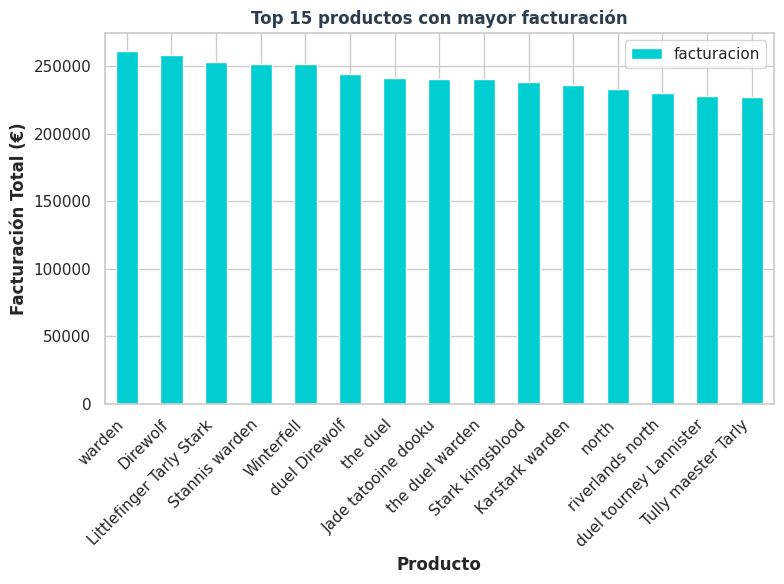

In [ ]:
## Grafico de barras top productos "facturación"
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

grafico_top15 = top_15.plot.bar(
    x="product_name",
    y="facturacion",
    figsize=(8, 6),
    color="#00CED1"
)

plt.xticks(rotation=45, ha="right")

grafico_top15.set_title("Top 15 productos con mayor facturación",
                     fontweight='bold', color='#2c3e50')
grafico_top15.set_ylabel("Facturación Total (€)",
                      fontweight='semibold')
grafico_top15.set_xlabel("Producto",
                      fontweight='semibold')

plt.tight_layout()
plt.show()

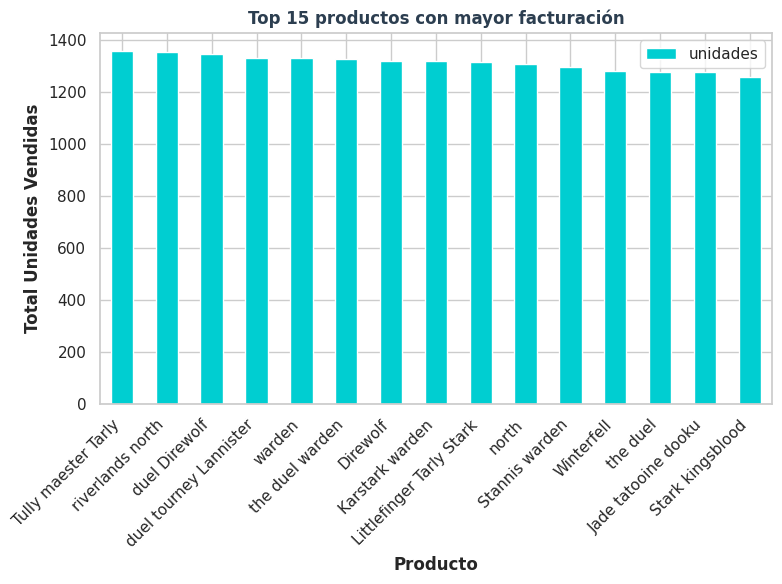

In [ ]:
## Grafico de lineas top productos "unidades"
sns.set_theme(style="whitegrid")

top_15_ordenado = top_15.sort_values("unidades", ascending=False)

grafico_top15 = top_15_ordenado.plot.bar(
    x="product_name",
    y="unidades",
    figsize=(8, 6),
    color="#00CED1"
)

plt.xticks(rotation=45, ha="right")

grafico_top15.set_title("Top 15 productos con mayor facturación",
                     fontweight='bold', color='#2c3e50')
grafico_top15.set_ylabel("Total Unidades Vendidas",
                      fontweight='semibold')
grafico_top15.set_xlabel("Producto",
                      fontweight='semibold')

plt.tight_layout()
plt.show()

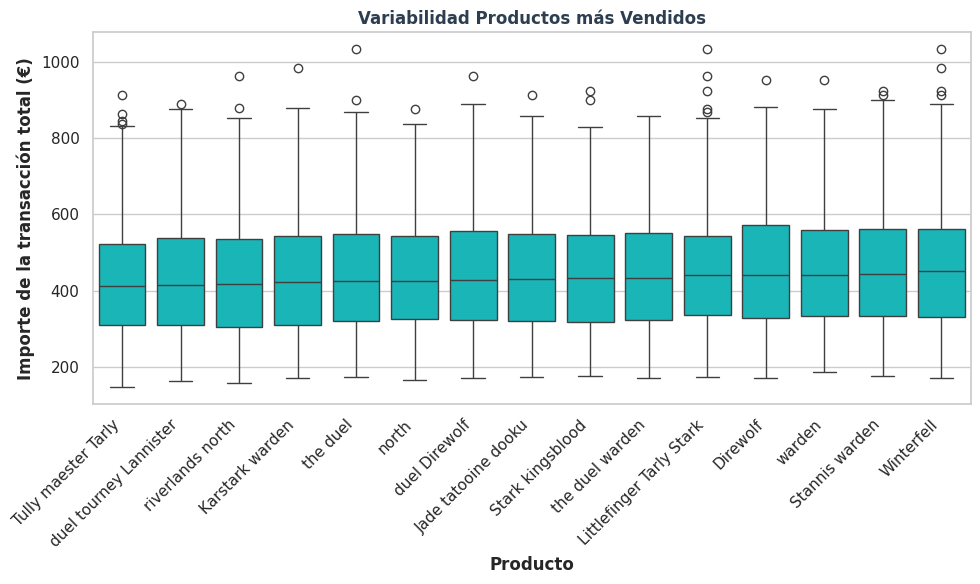

In [ ]:
## Grafico boxplot para variabilidad de top productos
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

orden_g = datos_top.groupby("product_name")["amount"].median().sort_values().index

grafico_variabilidad = sns.boxplot(
    data=datos_top,
    x="product_name",
    y="amount",
    color="#00CED1",
    order=orden_g
)

plt.xticks(rotation=45, ha="right")

grafico_variabilidad.set_title("Variabilidad Productos más Vendidos",
                     fontweight='bold', color='#2c3e50')
grafico_variabilidad.set_ylabel("Importe de la transacción total (€)",
                      fontweight='semibold')
grafico_variabilidad.set_xlabel("Producto",
                      fontweight='semibold')

plt.tight_layout()
plt.show()

##### 💡 Análisis de resultados

*   Los productos del Top 15 presentan niveles de facturación bastante similares. Esto indica que la facturación total no depende de uno o dos productos concretos, sino que está bastante repartida dentro de este grupo.

*   Al comparar la facturación con las unidades vendidas, se observa que un mayor volumen de ventas no implica necesariamente una mayor facturación. El caso más claro es Tully maester Tarly, que es el producto con más unidades vendidas pero el que genera menor facturación dentro del Top 15, lo que sugiere un precio unitario más bajo que el de otros productos.

*   En cuanto a la variabilidad, los productos aparecen en transacciones con rangos de importe bastante similares. También se observan valores atípicos en varios productos, incluido Tully maester Tarly, lo que indica que en algunas ocasiones estos productos forman parte de transacciones de importe considerablemente superior al habitual.

*   Como limitación, el boxplot utiliza el amount total de la transacción, por lo que no mide directamente la variabilidad de los ingresos generados por cada producto, sino la variabilidad del importe de las transacciones en las que aparecen.

*   Para el negocio, convendría analizar en conjunto volumen de ventas, precio y facturación, ya que un producto muy vendido no tiene por qué ser el más rentable.

#### ⚡ 4. Patrones horarios en ventas

##### 💻 Código inicial

In [ ]:
## Crear función para calcular "franje_horaria"
def asignar_franja(timestamp):
    hora = pd.to_datetime(timestamp).hour

    if 0 <= hora < 6:
        return "early morning"
    elif 6 <= hora < 12:
        return "morning"
    elif 12 <= hora < 18:
        return "afternoon"
    else:
        return "evening/night"

In [ ]:
## Comprobar uso de la funcion
prueba_franja = asignar_franja("2026-10-21 14:45:00")
prueba_franja

'afternoon'

In [ ]:
## Crear nuevo df con columna "franja_horaria"
transacciones_time = transacciones.copy()

transacciones_time["franja_horaria"] = transacciones_time["timestamp"].apply(asignar_franja)

transacciones_time.sample()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km,franja_horaria
77103,4ED2E739-1848-4C25-A869-E8E46753F41C,CcS-8888,b-2390,2021-08-18 09:43:46,434.2,0,"85, 39, 68",4307,43.250735,-79.864819,28.29,35.85,0.0,store,SUMMER_TRAVEL,pos,1,NaN,2358.65,morning


In [ ]:
## Cambios previos a la creación del crosstab
transacciones_time["timestamp"] = pd.to_datetime(transacciones_time["timestamp"])

transacciones_time = transacciones_time[transacciones_time["declined"] == 0]


In [ ]:
## Creación columna "week_day"
transacciones_time["week_day"] = transacciones_time["timestamp"].dt.day_name()

transacciones_time.sample()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km,franja_horaria,week_day
17627,2E00D3F3-EEFF-4D72-9D86-6185A9BB6256,CcS-5883,b-2558,2019-04-06 19:26:20,343.16,0,"58, 89",1302,41.975027,12.926021,...,61.88,0.0,store,SPRING_FLASH,pos,0,NaN,31.81,evening/night,Saturday


In [ ]:
## Creación columna "year"
transacciones_time["year"] = transacciones_time["timestamp"].dt.year

transacciones_time.sample()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km,franja_horaria,week_day,year
18322,DB3C744C-6939-4CE6-BDA6-AC2DF9F39299,CcU-3421,b-2486,2019-03-23 17:12:01,300.47,0,"38, 55, 83, 93",206,43.643238,-79.3394,...,0.0,store,NO_CAMPAIGN,pos,0,NaN,3.69,afternoon,Saturday,2019


In [ ]:
## Creación de crosstab_days
cross_days = pd.crosstab(transacciones_time["week_day"], transacciones_time["franja_horaria"])

cross_days

franja_horaria,afternoon,early morning,evening/night,morning
week_day,,,,
Friday,3571,3533,3517,3517
Monday,3469,3482,3570,3475
Saturday,3485,3631,3519,3586
Sunday,3665,3558,3446,3502
Thursday,3612,3558,3563,3655
Tuesday,3572,3488,3512,3473
Wednesday,3545,3631,3447,3530


In [ ]:
## Creación de crosstab_years
cross_years = pd.crosstab(transacciones_time["year"], transacciones_time["franja_horaria"])

cross_years

franja_horaria,afternoon,early morning,evening/night,morning
year,,,,
2015,2425,2431,2478,2443
2016,2481,2454,2374,2461
2017,2531,2425,2421,2456
2018,2487,2496,2430,2410
2019,2526,2437,2429,2536
2020,2453,2591,2520,2445
2021,2569,2569,2505,2555
2022,2497,2548,2539,2431
2023,2448,2492,2434,2528


##### 📈 Visualización

In [ ]:
## Reordenación de valores

orden_dias = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

cross_days = cross_days.reindex(orden_dias)
cross_days = cross_days[["early morning", "morning", "afternoon", "evening/night"]]

cross_years = cross_years[["early morning", "morning", "afternoon", "evening/night"]]

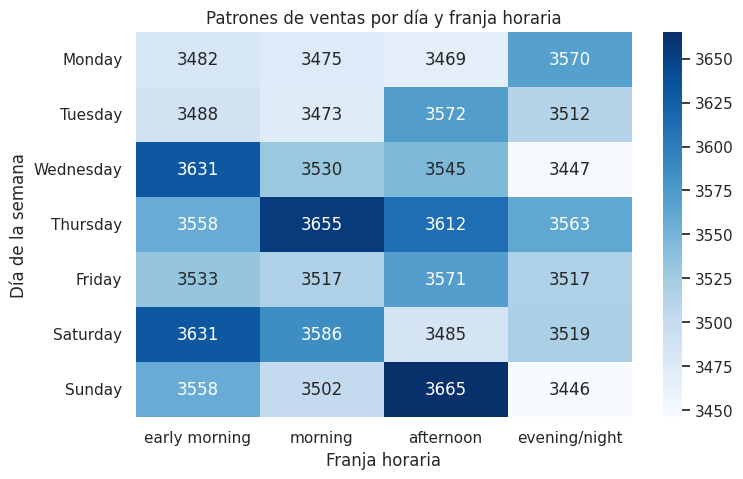

In [ ]:
## Creación de heatmap "crosstab_days"
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.heatmap(cross_days, annot=True, fmt="d", cmap="Blues")
plt.title("Patrones de ventas por día y franja horaria")
plt.xlabel("Franja horaria")
plt.ylabel("Día de la semana")
plt.show()

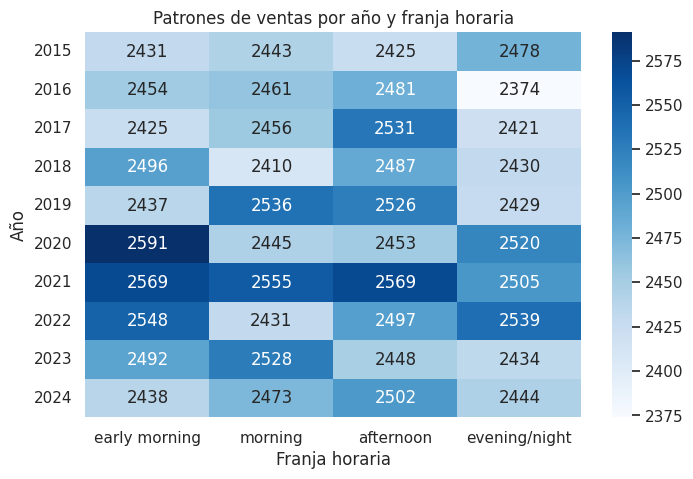

In [ ]:
## Creación de heatmap "cross_years"
plt.figure(figsize=(8, 5))
sns.heatmap(cross_years, annot=True, fmt="d", cmap="Blues")
plt.title("Patrones de ventas por año y franja horaria")
plt.xlabel("Franja horaria")
plt.ylabel("Año")
plt.show()

##### 💡 Análisis de resultados

*   No se observa un patrón horario dominante y/o constante en las ventas.

*   Al comparar los años, la actividad se mantiene equilibrada entre las distintas franjas horarias, con algunos picos puntuales como la madrugada de 2020 o una actividad algo superior en varias franjas durante 2021, pero sin que una franja concreta destaque de forma sostenida a lo largo del tiempo.

*   El análisis por días de la semana muestra un comportamiento similar. Las diferencias entre días y franjas son reducidas, aunque aparecen algunos valores ligeramente superiores, como el domingo por la tarde, el jueves por la mañana o el miércoles y sábado durante la madrugada. Estos picos no parecen suficientes para establecer un patrón general.

*   Estos resultados indican que no sería recomendable concentrar las acciones comerciales únicamente en una franja horaria o día concreto. La actividad está bastante repartida, aunque los picos identificados podrían analizarse con más detalle para comprobar si coinciden con campañas, promociones u otros factores específicos que puedan explicar esos incrementos.

# **Nivell 2**: Anàlisi amb dades enriquides i estructures múltiples

## **Exercici 1**: Anàlisi de productes i captació d'usuaris

### 🚩 Problema planteado

🎯 **Objectiu**: Analitzar el rendiment dels productes combinant ingressos, estabilitat i capacitat de captació de nous usuaris, amb l'objectiu de detectar possibles riscos de negoci associats a concentració excessiva d'ingressos, dependència d'usuaris recurrents i manca de creixement en base d'usuaris.

Els productes que generen més ingressos també impulsen el creixement del negoci mitjançant la captació de nous usuaris, o bé el negoci depèn principalment d'usuaris recurrents comprant els mateixos productes?

<br>

**Passos orientatius**:

1. Combina les taules necessàries.
2. Defineix un criteri de nou usuari si la transacció analitzada és la primera cronològicament que realitza al sistema es_nou_usuari = True / False.
3. Agrega la informació per producte i calcula les mètriques següents:

    *   Ingressos totals.
    *   Variabilitat dels ingressos.
    *   Nombre de nous usuaris.
    *   Percentatge de nous usuaris sobre el total de compradors del producte.

4. Creació d'una tipologia analítica de productes a partir de les mètriques calculades, per exemple:

    *   Captador: alta captació de nous usuaris.
    *   Recurrent: ingressos elevats però baixa captació.
    *   Emergent: baixa facturació però bona captació.
    *   Estancat: baixos ingressos i baixa captació.

5. Construeix una visualització que permeti analitzar la relació entre les dimensions principals. Per exemple, un scatter plot amb:

    *   Eix X → ingressos totals per producte.
    *   Eix Y → nombre de nous usuaris.
    *   Mida del punt → variabilitat dels ingressos.
    *   Color del punt → tipologia analítica del producte.

<br>

📌 **Nota important**

No es tracta només de mostrar gràfics, sinó d'interpretar què implica per al negoci no captar nous usuaris.

### 🧩 Desarrollo paso a paso

#### ⚡Cargar datos

In [32]:
## Cargar transactions y darle un nuevo nombre
import pandas as pd
transacciones_n2_e1 = pd.read_csv("/content/N2-Ex.8_transactions.csv", sep=";")

In [33]:
## Comprobar datos
transacciones_n2_e1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                100000 non-null  object 
 1   card_id           100000 non-null  object 
 2   business_id       100000 non-null  object 
 3   timestamp         100000 non-null  object 
 4   amount            100000 non-null  float64
 5   declined          100000 non-null  int64  
 6   product_ids       100000 non-null  object 
 7   user_id           100000 non-null  int64  
 8   lat               100000 non-null  float64
 9   longitude         100000 non-null  float64
 10  discount_amount   100000 non-null  float64
 11  tax_amount        100000 non-null  float64
 12  shipping_amount   100000 non-null  float64
 13  channel           100000 non-null  object 
 14  campaign_id       100000 non-null  object 
 15  device_type       100000 non-null  object 
 16  is_international  100

In [34]:
## Transformar "timstamp"
transacciones_n2_e1["timestamp"] = pd.to_datetime(transacciones_n2_e1["timestamp"])

transacciones_n2_e1 = transacciones_n2_e1[transacciones_n2_e1["declined"] == 0]

#### ⚡Creación `nuevo_usuario`

In [35]:
## Encontrar la primera compra de cada usuario
transacciones_n2_e1["primera_compra"] = (
    transacciones_n2_e1.groupby("user_id")["timestamp"].transform("min")
)

transacciones_n2_e1.head()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km,primera_compra
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018-12-12 08:05:17,176.45,0,"75, 73, 98",2313,59.620510,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25,2015-03-05 09:59:07
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57,2015-03-13 19:15:07
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018-11-04 23:16:18,548.77,0,"92, 85, 36, 23",3834,39.224213,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24,2015-09-07 16:06:55
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68,2015-01-17 16:50:54
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46,2015-01-28 07:50:04


In [36]:
## Crear la variable "nuevo_usuario"
transacciones_n2_e1["nuevo_usuario"] = (
    transacciones_n2_e1["timestamp"] == transacciones_n2_e1["primera_compra"]
)

transacciones_n2_e1.head()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km,primera_compra,nuevo_usuario
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018-12-12 08:05:17,176.45,0,"75, 73, 98",2313,59.620510,16.559977,...,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25,2015-03-05 09:59:07,False
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,...,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57,2015-03-13 19:15:07,False
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018-11-04 23:16:18,548.77,0,"92, 85, 36, 23",3834,39.224213,-0.288066,...,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24,2015-09-07 16:06:55,False
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,...,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68,2015-01-17 16:50:54,False
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,...,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46,2015-01-28 07:50:04,False


#### ⚡Combinación de tablas

In [37]:
## Cargar tabla puente
t_puente = pd.read_csv("/content/N2-Ex.8_trans_products.csv", sep=";")

In [38]:
## Carga productos y transformaciones necesarias
productos_n2_e1 = pd.read_csv("/content/N2-Ex.8_products.csv", sep=";")

In [39]:
## Hacer transformaciones necesarias
transacciones_n2_e1 = transacciones_n2_e1.rename(columns={"id": "transaction_id"})
productos_n2_e1 = productos_n2_e1.rename(columns={"id": "product_id"})

In [40]:
## Hacer merge
merge_trans = (
    transacciones_n2_e1
    .merge(t_puente, left_on="transaction_id", right_on="transaction_id")
    .merge(productos_n2_e1, on="product_id")
)

merge_trans.head()

,transaction_id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,...,product_id,product_name,price,colour,weight,warehouse_id,category,brand,cost,launch_date
0,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,...,3,duel tourney Lannister,$171.13,#d8d8d8,1.5,WH-2,Food,Daily Pantry,$107.07,2013-08-18
1,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,...,5,skywalker ewok,$171.22,#dbdbdb,3.2,WH-0,Home,NordHaus,$83.69,2014-07-17
2,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,...,27,Stannis riverlands,$172.93,#7a7a7a,1.5,WH-22,Home,NordHaus,$83.83,2014-01-08
3,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,...,38,ewok sith,$55.43,#666666,2.0,WH-33,Electronics,Nexa,$36.05,2014-12-01
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,...,32,north,$178.28,#0f0f0f,1.4,WH-27,Home,CasaNova,$98.47,2013-12-15


In [41]:
## Comprobaciones nueva tabla
merge_trans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128637 entries, 0 to 128636
Data columns (total 31 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    128637 non-null  object        
 1   card_id           128637 non-null  object        
 2   business_id       128637 non-null  object        
 3   timestamp         128637 non-null  datetime64[ns]
 4   amount            128637 non-null  float64       
 5   declined          128637 non-null  int64         
 6   product_ids       128637 non-null  object        
 7   user_id           128637 non-null  int64         
 8   lat               128637 non-null  float64       
 9   longitude         128637 non-null  float64       
 10  discount_amount   128637 non-null  float64       
 11  tax_amount        128637 non-null  float64       
 12  shipping_amount   128637 non-null  float64       
 13  channel           128637 non-null  object        
 14  camp

In [42]:
## Trasnformación de columna "price"
merge_trans["price"] = merge_trans["price"].str.replace("$", "", regex=False)
merge_trans["price"] = merge_trans["price"].astype(float)

merge_trans["price"].dtype

dtype('float64')

#### ⚡Datos de producto y métricas básicas

In [44]:
## Calculo de ingresos totales por producto
ingresos_producto = (
    merge_trans.groupby(["product_id", "product_name"])["price"].sum()
)

ingresos_producto.head()

,,price
product_id,product_name,
1,Direwolf Stannis,201548.61
2,Tarly Stark,12547.92
3,duel tourney Lannister,225720.47
4,warden south duel,94319.68
5,skywalker ewok,220873.80


In [48]:
## Nueva tabla con agrupación por año
ingresos_anuales = (
    merge_trans.groupby([
        "product_id", "product_name", merge_trans["timestamp"].dt.year]
                        )["price"].sum()
)

ingresos_anuales.head()

product_id  product_name      timestamp
1           Direwolf Stannis  2015         19010.98
                              2016         20138.75
                              2017         22555.40
                              2018         18527.65
                              2019         18849.87
Name: price, dtype: float64

In [50]:
## Calculo de variabilidad de igresos por producto y año
std_producto = ingresos_anuales.groupby(
    ["product_id", "product_name"]
).std()

media_producto = ingresos_anuales.groupby(
    ["product_id", "product_name"]
).mean()

variabilidad_producto = (
    std_producto / media_producto * 100
).round(2)


variabilidad_producto_df = variabilidad_producto.reset_index()
variabilidad_producto_df = variabilidad_producto_df.rename(
    columns={"price": "variabilidad_ingresos"}
)

variabilidad_producto_df.head()

,product_id,product_name,variabilidad_ingresos
0,1,Direwolf Stannis,8.26
1,2,Tarly Stark,7.50
2,3,duel tourney Lannister,9.57
3,4,warden south duel,10.17
4,5,skywalker ewok,4.53


In [51]:
## Calcular nuevos usuarios por producto
filtro_nuevos_usuarios = merge_trans[merge_trans["nuevo_usuario"] == True]

nu_producto = filtro_nuevos_usuarios.groupby([
        "product_id", "product_name"])["user_id"].nunique()

nu_producto.head()

,,user_id
product_id,product_name,
1,Direwolf Stannis,58
2,Tarly Stark,65
3,duel tourney Lannister,71
4,warden south duel,61
5,skywalker ewok,78


In [52]:
## Calcular total de usuarios por producto
u_producto = merge_trans.groupby([
        "product_id", "product_name"])["user_id"].nunique()

u_producto.head()

,,user_id
product_id,product_name,
1,Direwolf Stannis,1099
2,Tarly Stark,1174
3,duel tourney Lannister,1121
4,warden south duel,1132
5,skywalker ewok,1135


In [53]:
## Porcentaje de nuevos usuarios sobre el total de compradores
porcentaje = (nu_producto / u_producto) * 100

porcentaje = porcentaje.round(2)

porcentaje.head()

,,user_id
product_id,product_name,
1,Direwolf Stannis,5.28
2,Tarly Stark,5.54
3,duel tourney Lannister,6.33
4,warden south duel,5.39
5,skywalker ewok,6.87


#### ⚡Creación de tabla combinada "productos_enriquecido"

In [54]:
## Empezar con "inregsos_productos"
productos_enriquecido = ingresos_producto.reset_index()
productos_enriquecido = productos_enriquecido.rename(columns={"price": "ingresos_totales"})

productos_enriquecido.head()

,product_id,product_name,ingresos_totales
0,1,Direwolf Stannis,201548.61
1,2,Tarly Stark,12547.92
2,3,duel tourney Lannister,225720.47
3,4,warden south duel,94319.68
4,5,skywalker ewok,220873.80


In [55]:
## Modificación de "nuevos_usuarios" previo merge
nuevos_usuarios = nu_producto.reset_index()
nuevos_usuarios = nuevos_usuarios.rename(columns={"user_id": "nuevos_usuarios"})

nuevos_usuarios.head()

,product_id,product_name,nuevos_usuarios
0,1,Direwolf Stannis,58
1,2,Tarly Stark,65
2,3,duel tourney Lannister,71
3,4,warden south duel,61
4,5,skywalker ewok,78


In [56]:
## Modificación de "u_productos" previo merge
total_usuarios = u_producto.reset_index()
total_usuarios = total_usuarios.rename(columns={"user_id": "total_usuarios"})

total_usuarios.head()

,product_id,product_name,total_usuarios
0,1,Direwolf Stannis,1099
1,2,Tarly Stark,1174
2,3,duel tourney Lannister,1121
3,4,warden south duel,1132
4,5,skywalker ewok,1135


In [57]:
## Modificación de "porcentaje" previo merge
porcentaje_nuevos = porcentaje.reset_index()
porcentaje_nuevos = porcentaje_nuevos.rename(columns={"user_id": "porcentaje_nuevos"})

porcentaje_nuevos.head()

,product_id,product_name,porcentaje_nuevos
0,1,Direwolf Stannis,5.28
1,2,Tarly Stark,5.54
2,3,duel tourney Lannister,6.33
3,4,warden south duel,5.39
4,5,skywalker ewok,6.87


In [58]:
## Set index de las tablas para poder hacer "concat"
productos_enriquecido = productos_enriquecido.set_index(["product_id", "product_name"])
variabilidad_producto_df = variabilidad_producto_df.set_index(["product_id", "product_name"])
nuevos_usuarios = nuevos_usuarios.set_index(["product_id", "product_name"])
total_usuarios = total_usuarios.set_index(["product_id", "product_name"])
porcentaje_nuevos = porcentaje_nuevos.set_index(["product_id", "product_name"])


In [59]:
## Concat final "productos_enriquecidos"
productos_enriquecido = pd.concat(
    [
        productos_enriquecido,
        variabilidad_producto_df,
        nuevos_usuarios,
        total_usuarios,
        porcentaje_nuevos
    ],
    axis=1
)

productos_enriquecido = productos_enriquecido.reset_index()

productos_enriquecido.head()

,product_id,product_name,ingresos_totales,variabilidad_ingresos,nuevos_usuarios,total_usuarios,porcentaje_nuevos
0,1,Direwolf Stannis,201548.61,8.26,58,1099,5.28
1,2,Tarly Stark,12547.92,7.50,65,1174,5.54
2,3,duel tourney Lannister,225720.47,9.57,71,1121,6.33
3,4,warden south duel,94319.68,10.17,61,1132,5.39
4,5,skywalker ewok,220873.80,4.53,78,1135,6.87


#### ⚡Creación de tipología analitica

In [60]:
## Calculo de mediana de ingresos y nuevos usuarios
mediana_ingresos = ingresos_producto.median()
mediana_usuarios = porcentaje.median()

display(mediana_ingresos, mediana_usuarios)

128017.27

5.805

Dealle de la tipología a usar:

- ingresos altos + captación alta  → **Captador**
- ingresos altos + captación baja  → **Recurrente**
- ingresos bajos + captación alta  → **Emergente**
- ingresos bajos + captación baja  → **Estancado**

In [61]:
## Definir función para asignar tipología analítica de producto
def asignar_tipologia(ingresos, captacion):
  median_ingresos = 128017.27
  median_captacion = 5.805

  if (ingresos >= median_ingresos) & (captacion >= median_captacion):
    return "Captador"

  if (ingresos >= median_ingresos) & (captacion < median_captacion):
    return "Recurrente"

  if (ingresos < median_ingresos) & (captacion >= median_captacion):
    return "Emergente"

  if (ingresos < median_ingresos) & (captacion < median_captacion):
    return "Estancado"


In [62]:
## Prueba de uso función "asignar_tipologia"
prueba_at = asignar_tipologia(500, 4)
prueba_at

'Estancado'

In [63]:
## Creación nueva columna "tipologia_analitica" en "productos_enriquecido"
productos_enriquecido["tipologia_analitica"] = productos_enriquecido.apply(
    lambda fila: asignar_tipologia(
        fila["ingresos_totales"],
        fila["porcentaje_nuevos"]
    ),
    axis=1
)
productos_enriquecido.head()

,product_id,product_name,ingresos_totales,variabilidad_ingresos,nuevos_usuarios,total_usuarios,porcentaje_nuevos,tipologia_analitica
0,1,Direwolf Stannis,201548.61,8.26,58,1099,5.28,Recurrente
1,2,Tarly Stark,12547.92,7.50,65,1174,5.54,Estancado
2,3,duel tourney Lannister,225720.47,9.57,71,1121,6.33,Captador
3,4,warden south duel,94319.68,10.17,61,1132,5.39,Estancado
4,5,skywalker ewok,220873.80,4.53,78,1135,6.87,Captador


### 📈 Visualización

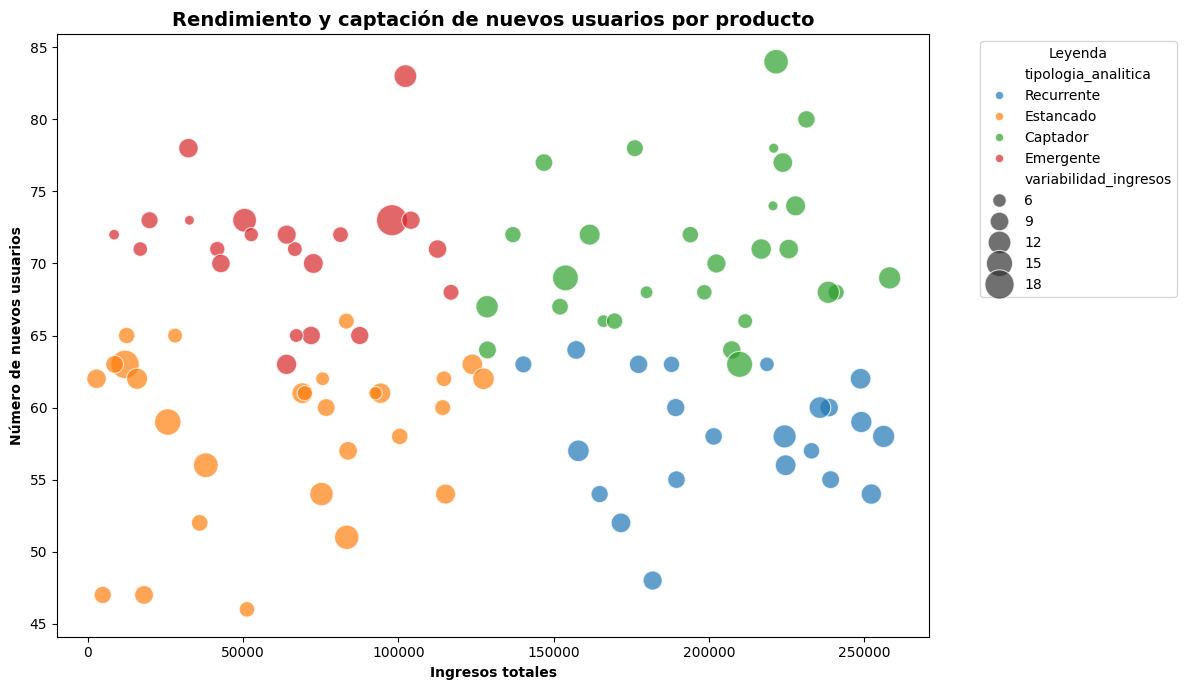

In [64]:
## Creación de gráfico tipo Scatterplot de acuerdo a directrices del ejercicio
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=productos_enriquecido,
    x="ingresos_totales",
    y="nuevos_usuarios",
    size="variabilidad_ingresos",
    hue="tipologia_analitica",
    sizes=(50, 500),
    alpha=0.7
)

plt.title(
    "Rendimiento y captación de nuevos usuarios por producto",
    fontweight="bold",
    fontsize=14
)

plt.xlabel(
    "Ingresos totales",
    fontweight="bold"
)

plt.ylabel(
    "Número de nuevos usuarios",
    fontweight="bold"
)

plt.legend(
    title="Leyenda",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.gcf().set_facecolor("white")
plt.gca().set_facecolor("white")

plt.tight_layout()
plt.show()

### 💡 Análisis de resultados

**Gráfico Scatterplot**
- El gráfico permite comparar el rendimiento de cada producto combinando facturación, captación de nuevos usuarios y estabilidad de los ingresos.
- La tipología en colores facilita la visualización de patrones, dentro de las limitaciones de un gráfico estático.
- La distribución entre tipologías es bastante equilibrada, sin que una categoría domine claramente sobre las demás. Este equilibrio puede explicarse con la forma de calcular dicha tipología, a partir de las medianas de ingresos y captación, lo que tiende a dividir los productos de forma relativamente homogénea.

<br>

**Tipología Analítica**
- Los productos recurrentes aportan ingresos importantes y relativamente estables, pero dependen más de usuarios que ya eran clientes del negocio.
- Los productos captadores combinan ingresos altos con buena captación de nuevos usuarios. Por eso son importantes para el negocio, porque además de vender bien, ayudan a atraer clientes nuevos. Sin embargo, sus ingresos pueden ser menos estables debido a la variabilidad observada.
- Los productos emergentes atraen una cantidad considerable de nuevos usuarios, pero generan menos ingresos que los productos recurrentes y captadores. Además, en el gráfico se ve una variabilidad menor, por lo que sus ingresos parecen más estables.
- Los productos estancados generan pocos ingresos y presentan una baja captación de nuevos usuarios. Además, muestran una variabilidad baja, por lo que sus ingresos son relativamente estables. Sin embargo, esta estabilidad no resulta especialmente positiva, ya que se mantiene sobre niveles de facturación bajos.

<br>

**Implicaciones para el negocio**
- Riesgo de generar una dependencia excesiva de los productos recurrentes si se descuida la captación de nuevos usuarios.
- A medio plazo, una baja captación puede limitar el crecimiento del negocio, aunque los productos recurrentes mantengan ingresos altos actualmente.
- En conjunto, los productos con mayores ingresos no dependen exclusivamente de la captación de nuevos usuarios. Tanto captadores como recurrentes presentan niveles altos de facturación, lo que indica que el negocio combina ingresos procedentes de usuarios nuevos y existentes. Sin embargo, una reducción de la captación podría aumentar la dependencia de los usuarios recurrentes y limitar el crecimiento.

## **Exercici 2**: Anàlisi geogràfica company–usuari i oportunitats d'expansió

### 🚩 Problema planteado

🎯 **Objectiu**: Analitzar la relació entre el país de les companyies venedores, el país de residència dels usuaris i el flux de compra entre països.

El negoci està basat en mercats locals (mateix país usuari–companyia) o hi ha una oportunitat real d'expansió internacional obrint més companyies en certs països?

<br>

**Passos orientatius**:

1. Combina les taules necessàries.
2. Crea una variable clau d'anàlisi: compra_local = True/False.
3. Analitza el comportament global:

    *   Percentatge de transaccions locals vs internacionals.
    *   Percentatge de facturació local vs internacional.

4. Anàlisi per país de l'usuari, per cada país d'usuari:

    *   % de compres a companyies del mateix país.
    *   % de compres a companyies estrangeres.
    *   Import total comprat.

5. Anàlisi per país de companyia, per cada país de companyia calcula quina part de la seva facturació ve de:

    *   Usuaris locals.
    *   Usuaris estrangers.

6. Escull una visualització que expliqui clarament el fenomen.
7. Interpretació estratègica:

<br>

*   En quins països valdria la pena obrir més companyies locals?
*   Hi ha països amb demanda però poca oferta local?
*   El negoci depèn massa de companyies d'un sol país?
*   Obrir companyies locals reduiria fricció o milloraria conversió?

### 🧩 Desarrollo paso a paso

#### ⚡Cargar datos

In [3]:
## Cargar tablas necesarias
import pandas as pd
trans_n2_e2 = pd.read_csv("/content/N2-Ex.8_transactions.csv", sep=";")
companies_n2_e2 = pd.read_csv("/content/N2-Ex.8_companies.csv", sep=";")
users_n2_e2 = pd.read_csv("/content/N2-Ex.8_users.csv", encoding="latin1", sep=";")

In [4]:
## Comprobación de datos
trans_n2_e2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                100000 non-null  object 
 1   card_id           100000 non-null  object 
 2   business_id       100000 non-null  object 
 3   timestamp         100000 non-null  object 
 4   amount            100000 non-null  float64
 5   declined          100000 non-null  int64  
 6   product_ids       100000 non-null  object 
 7   user_id           100000 non-null  int64  
 8   lat               100000 non-null  float64
 9   longitude         100000 non-null  float64
 10  discount_amount   100000 non-null  float64
 11  tax_amount        100000 non-null  float64
 12  shipping_amount   100000 non-null  float64
 13  channel           100000 non-null  object 
 14  campaign_id       100000 non-null  object 
 15  device_type       100000 non-null  object 
 16  is_international  100

In [5]:
## Comprobación de datos
companies_n2_e2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   company_id               100 non-null    object
 1   company_name             100 non-null    object
 2   phone                    100 non-null    object
 3   email                    100 non-null    object
 4   country                  100 non-null    object
 5   website                  100 non-null    object
 6   merchant_category        100 non-null    object
 7   merchant_price_position  100 non-null    object
dtypes: object(8)
memory usage: 6.4+ KB


In [6]:
## Comprobación de datos
users_n2_e2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            5000 non-null   int64 
 1   name          5000 non-null   object
 2   surname       5000 non-null   object
 3   phone         5000 non-null   object
 4   email         5000 non-null   object
 5   birth_date    5000 non-null   object
 6   country       5000 non-null   object
 7   city          5000 non-null   object
 8   postal_code   5000 non-null   object
 9   address       5000 non-null   object
 10  signup_date   5000 non-null   object
 11  user_segment  5000 non-null   object
 12  income_band   5000 non-null   object
 13  region        5000 non-null   object
dtypes: int64(1), object(13)
memory usage: 547.0+ KB


#### ⚡Combinación de tablas

In [7]:
## Hacer merge
merge_n2_e2 = (
    trans_n2_e2
    .merge(companies_n2_e2, left_on="business_id", right_on="company_id")
    .merge(users_n2_e2, left_on="user_id", right_on="id")
)

merge_n2_e2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 41 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id_x                     100000 non-null  object 
 1   card_id                  100000 non-null  object 
 2   business_id              100000 non-null  object 
 3   timestamp                100000 non-null  object 
 4   amount                   100000 non-null  float64
 5   declined                 100000 non-null  int64  
 6   product_ids              100000 non-null  object 
 7   user_id                  100000 non-null  int64  
 8   lat                      100000 non-null  float64
 9   longitude                100000 non-null  float64
 10  discount_amount          100000 non-null  float64
 11  tax_amount               100000 non-null  float64
 12  shipping_amount          100000 non-null  float64
 13  channel                  100000 non-null  object 
 14  campa

In [8]:
## Crear nueva tabla
relacion_paises = merge_n2_e2[["id_x",
                               "user_id",
                               "company_id",
                               "company_name",
                               "amount",
                               "declined",
                               "country_y",
                               "country_x"]]

relacion_paises = relacion_paises.rename(columns={
    "id_x": "transaction_id",
    "country_y": "country_user",
    "country_x": "country_company"})

relacion_paises.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   transaction_id   100000 non-null  object 
 1   user_id          100000 non-null  int64  
 2   company_id       100000 non-null  object 
 3   company_name     100000 non-null  object 
 4   amount           100000 non-null  float64
 5   declined         100000 non-null  int64  
 6   country_user     100000 non-null  object 
 7   country_company  100000 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 6.1+ MB


#### ⚡Creación de variable `local_purchase`

In [9]:
## Creación de la variable "local_purchase"
relacion_paises["local_purchase"] = relacion_paises[
    "country_user"] == relacion_paises["country_company"]

relacion_paises.sample(5)

,transaction_id,user_id,company_id,company_name,amount,declined,country_user,country_company,local_purchase
89967,99C8DA91-28D0-4C1B-B049-C0D74785B781,4293,b-2546,Lorem Ipsum Dolor Corp.,74.88,0,Portugal,Sweden,False
6406,C57CC832-A1D9-44D9-A3DF-B156EFE899B0,799,b-2246,Sed Nunc Ltd,378.63,0,Poland,United Kingdom,False
78357,9B2AF642-13E7-406A-81C4-0DBFB496A973,1700,b-2606,Sed Est Corp.,185.89,0,United States,Canada,False
28176,C56E9F4D-276F-48B3-A89D-EDA6EC43076A,2219,b-2350,Aliquet Vel Vulputate Incorporated,498.56,0,Netherlands,Netherlands,True
16627,B476F012-343F-4C3F-B0B5-2672A67A7992,1892,b-2330,Donec Fringilla PC,143.49,0,Netherlands,France,False


In [10]:
## Comprobaciones
relacion_paises["local_purchase"].value_counts()

,count
local_purchase,
False,88138
True,11862


#### ⚡Analisis de comportamiento

In [11]:
## Filtrar transacciones completadas
relacion_paises_clean = relacion_paises[relacion_paises["declined"] == 0]

relacion_paises_clean.head()

,transaction_id,user_id,company_id,company_name,amount,declined,country_user,country_company,local_purchase
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,2313,b-2466,Amet Lorem LLP,176.45,0,Sweden,Spain,False
1,09456357-8E9B-475A-8257-87A023699964,554,b-2342,Fringilla Porttitor Incorporated,206.65,0,France,Sweden,False
2,C47C7C84-C174-4973-A76B-825A9DB5582A,3834,b-2250,Amet Nulla Donec Corporation,548.77,0,Netherlands,Italy,False
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,1972,b-2610,Egestas Nunc Sed Limited,411.55,0,Spain,Italy,False
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,3097,b-2454,Justo Eu Arcu Ltd,410.65,0,Netherlands,Italy,False


In [12]:
## Calculo % de transacciones locales vs internacionales
porcentaje_transacciones = relacion_paises_clean[
    "local_purchase"].value_counts(normalize=True) * 100

porcentaje_transacciones = porcentaje_transacciones.reset_index()
porcentaje_transacciones = porcentaje_transacciones["proportion"].round(2)

porcentaje_transacciones

,proportion
0,88.13
1,11.87


In [13]:
## Calculo % de facturación local vs internacional
porcentaje_facturacion = relacion_paises_clean.groupby("local_purchase")["amount"].sum()

porcentaje_facturacion = porcentaje_facturacion.reset_index()

porcentaje_facturacion

,local_purchase,amount
0,False,25574073.22
1,True,3451309.19


In [14]:
## Calcular proporcion de cada rango
porcentaje_facturacion["proportion"] = porcentaje_facturacion[
    "amount"] / porcentaje_facturacion["amount"].sum() * 100

porcentaje_facturacion = porcentaje_facturacion["proportion"].round(2)

porcentaje_facturacion

,proportion
0,88.11
1,11.89


#### ⚡Análisis pais - usuarios

In [15]:
## Tipologia de compras por cada usuario
relacion_usuarios = relacion_paises_clean.groupby(
    ["country_user", "local_purchase"]).size()

relacion_usuarios

country_user    local_purchase
Canada          False             8888
                True               957
France          False             7907
                True               530
Germany         False             7186
                True              1467
Italy           False             7055
                True              1456
Netherlands     False             7168
                True              1721
Poland          False             8208
Portugal        False             8704
Spain           False             8727
                True               154
Sweden          False             6343
                True              1721
United Kingdom  False             7921
                True              1656
United States   False             9239
                True              2104
dtype: int64

In [16]:
## Corregir datos de tabla base
relacion_usuarios = relacion_usuarios.reset_index()
relacion_usuarios = relacion_usuarios.rename(columns = {0: "total_purchase"})

relacion_usuarios

,country_user,local_purchase,total_purchase
0,Canada,False,8888
1,Canada,True,957
2,France,False,7907
3,France,True,530
4,Germany,False,7186
5,Germany,True,1467
6,Italy,False,7055
7,Italy,True,1456
8,Netherlands,False,7168
9,Netherlands,True,1721


In [17]:
## Crear totales por pais
totales_pais = (relacion_usuarios.groupby("country_user")["total_purchase"]
    .sum().reset_index()
)

totales_pais = totales_pais.rename(columns = {"total_purchase": "total_country_purchases"})

totales_pais

,country_user,total_country_purchases
0,Canada,9845
1,France,8437
2,Germany,8653
3,Italy,8511
4,Netherlands,8889
5,Poland,8208
6,Portugal,8704
7,Spain,8881
8,Sweden,8064
9,United Kingdom,9577


In [18]:
## Unir datos de paises a tabla general
porcentaje_usuarios = relacion_usuarios.merge(
    totales_pais, on="country_user")

porcentaje_usuarios


,country_user,local_purchase,total_purchase,total_country_purchases
0,Canada,False,8888,9845
1,Canada,True,957,9845
2,France,False,7907,8437
3,France,True,530,8437
4,Germany,False,7186,8653
5,Germany,True,1467,8653
6,Italy,False,7055,8511
7,Italy,True,1456,8511
8,Netherlands,False,7168,8889
9,Netherlands,True,1721,8889


In [19]:
## Calcular los porcentajes
porcentaje_usuarios["proportion"] = porcentaje_usuarios[
    "total_purchase"] / porcentaje_usuarios["total_country_purchases"] * 100

porcentaje_usuarios["proportion"] = porcentaje_usuarios["proportion"].round(2)

porcentaje_usuarios

,country_user,local_purchase,total_purchase,total_country_purchases,proportion
0,Canada,False,8888,9845,90.28
1,Canada,True,957,9845,9.72
2,France,False,7907,8437,93.72
3,France,True,530,8437,6.28
4,Germany,False,7186,8653,83.05
5,Germany,True,1467,8653,16.95
6,Italy,False,7055,8511,82.89
7,Italy,True,1456,8511,17.11
8,Netherlands,False,7168,8889,80.64
9,Netherlands,True,1721,8889,19.36


In [20]:
## Importe total gastado por usuario y país
importe_pais = (relacion_paises_clean.groupby(
    "country_user")["amount"].sum().reset_index())

importe_pais.sort_values("amount", ascending=False)

,country_user,amount
10,United States,3049853.50
9,United Kingdom,2819917.93
7,Spain,2668434.76
4,Netherlands,2651840.50
0,Canada,2650339.29
6,Portugal,2615801.06
3,Italy,2585602.49
2,Germany,2550878.07
5,Poland,2491052.36
8,Sweden,2473822.29


In [21]:
## Calcular proporción de importe total gastado por usuario y país
importe_pais["proportion"] = (importe_pais["amount"] / importe_pais["amount"].sum()) * 100
importe_pais["proportion"] = importe_pais["proportion"].round(2)

importe_pais = importe_pais.rename(columns={"amount":"billing"})

importe_pais.sort_values("proportion", ascending=False)

,country_user,billing,proportion
10,United States,3049853.50,10.51
9,United Kingdom,2819917.93,9.72
7,Spain,2668434.76,9.19
4,Netherlands,2651840.50,9.14
0,Canada,2650339.29,9.13
6,Portugal,2615801.06,9.01
3,Italy,2585602.49,8.91
2,Germany,2550878.07,8.79
5,Poland,2491052.36,8.58
8,Sweden,2473822.29,8.52


#### ⚡Analisis país - compañía

In [22]:
## Tipologia de compras por cada compañia
relacion_companias = (relacion_paises_clean.groupby(
    ["country_company", "local_purchase"])["amount"].sum().reset_index())

relacion_companias

,country_company,local_purchase,amount
0,Australia,False,687532.20
1,Belgium,False,937789.26
2,Canada,False,297261.09
3,Canada,True,254806.44
4,China,False,235421.76
5,France,False,1252902.50
6,France,True,153765.65
7,Germany,False,3540549.43
8,Germany,True,444114.60
9,Ireland,False,707379.30


In [24]:
## Crear totales por pais
totales_fac_pais = (relacion_companias.groupby("country_company")["amount"]
    .sum().reset_index()
)

totales_fac_pais = totales_fac_pais.rename(columns = {"amount": "total_country_billing"})

totales_fac_pais

,country_company,total_country_billing
0,Australia,687532.20
1,Belgium,937789.26
2,Canada,552067.53
3,China,235421.76
4,France,1406668.15
5,Germany,3984664.03
6,Ireland,707379.30
7,Italy,4061060.93
8,Netherlands,4470873.59
9,New Zealand,696403.99


In [25]:
## Unir datos
porcentaje_paises = relacion_companias.merge(
    totales_fac_pais, on="country_company")

porcentaje_paises = porcentaje_paises.rename(columns = {"amount": "total_billing"})

porcentaje_paises

,country_company,local_purchase,total_billing,total_country_billing
0,Australia,False,687532.20,687532.20
1,Belgium,False,937789.26,937789.26
2,Canada,False,297261.09,552067.53
3,Canada,True,254806.44,552067.53
4,China,False,235421.76,235421.76
5,France,False,1252902.50,1406668.15
6,France,True,153765.65,1406668.15
7,Germany,False,3540549.43,3984664.03
8,Germany,True,444114.60,3984664.03
9,Ireland,False,707379.30,707379.30


In [26]:
## Calcular los porcentajes
porcentaje_paises["proportion"] = porcentaje_paises[
    "total_billing"] / porcentaje_paises["total_country_billing"] * 100

porcentaje_paises["proportion"] = porcentaje_paises["proportion"].round(2)

porcentaje_paises

,country_company,local_purchase,total_billing,total_country_billing,proportion
0,Australia,False,687532.20,687532.20,100.00
1,Belgium,False,937789.26,937789.26,100.00
2,Canada,False,297261.09,552067.53,53.85
3,Canada,True,254806.44,552067.53,46.15
4,China,False,235421.76,235421.76,100.00
5,France,False,1252902.50,1406668.15,89.07
6,France,True,153765.65,1406668.15,10.93
7,Germany,False,3540549.43,3984664.03,88.85
8,Germany,True,444114.60,3984664.03,11.15
9,Ireland,False,707379.30,707379.30,100.00


In [27]:
## Crear totales de facturación por país de compañía
totales_fac_pais = (
    relacion_companias.groupby("country_company")["amount"]
    .sum()
    .reset_index()
)

totales_fac_pais = totales_fac_pais.rename(
    columns={"amount": "total_country_billing"}
)

totales_fac_pais["proportion_global"] = (
    totales_fac_pais["total_country_billing"]
    / totales_fac_pais["total_country_billing"].sum()
) * 100

totales_fac_pais["proportion_global"] = (
    totales_fac_pais["proportion_global"].round(2)
)

totales_fac_pais.sort_values(
    "proportion_global",
    ascending=False
)

,country_company,total_country_billing,proportion_global
12,Sweden,4884250.39,16.83
8,Netherlands,4470873.59,15.40
13,United Kingdom,4065098.37,14.01
7,Italy,4061060.93,13.99
5,Germany,3984664.03,13.73
4,France,1406668.15,4.85
14,United States,1085266.88,3.74
1,Belgium,937789.26,3.23
10,Norway,798331.87,2.75
6,Ireland,707379.30,2.44


#### ⚡Analisis compras rechazadas

In [28]:
## Contabilizar % de compras rechazadas
calculo_declined = relacion_paises.groupby(
    ["local_purchase", "declined"]).size().reset_index(name="total_transactions")

calculo_declined

,local_purchase,declined,total_transactions
0,False,0,87346
1,False,1,792
2,True,0,11766
3,True,1,96


In [29]:
## Crear totales por tipo de compra
totales_declined = (calculo_declined.groupby("local_purchase")["total_transactions"]
    .sum().reset_index()
)

totales_declined

,local_purchase,total_transactions
0,False,88138
1,True,11862


In [30]:
## Unir datos
porcentaje_declined = calculo_declined.merge(
    totales_declined, on="local_purchase")


porcentaje_declined = porcentaje_declined.rename(
    columns={
        "local_purchase": "type",
        "declined": "status",
        "total_transactions_x": "total_transactions",
        "total_transactions_y": "total_transactions_global"
    }
)

porcentaje_declined["type"] = porcentaje_declined["type"].replace({
    False: "International",
    True: "Local"
})


porcentaje_declined["status"] = porcentaje_declined["status"].replace({
    0: "Accepted",
    1: "Declined"
})

porcentaje_declined

,type,status,total_transactions,total_transactions_global
0,International,Accepted,87346,88138
1,International,Declined,792,88138
2,Local,Accepted,11766,11862
3,Local,Declined,96,11862


In [31]:
## Calcular proporción
porcentaje_declined["proportion"] = (porcentaje_declined[
    "total_transactions"] / porcentaje_declined["total_transactions_global"]) * 100

porcentaje_declined["proportion"] = porcentaje_declined["proportion"].round(2)

porcentaje_declined

,type,status,total_transactions,total_transactions_global,proportion
0,International,Accepted,87346,88138,99.10
1,International,Declined,792,88138,0.90
2,Local,Accepted,11766,11862,99.19
3,Local,Declined,96,11862,0.81


### 📈 Visualización

In [ ]:
## Crear pivot table para grafico_a
pivot_grafico_users = porcentaje_usuarios.pivot_table(
    index="country_user",
    columns="local_purchase",
    values="proportion"
)

pivot_grafico_users

local_purchase,False,True
country_user,,
Canada,90.28,9.72
France,93.72,6.28
Germany,83.05,16.95
Italy,82.89,17.11
Netherlands,80.64,19.36
Poland,100.00,NaN
Portugal,100.00,NaN
Spain,98.27,1.73
Sweden,78.66,21.34


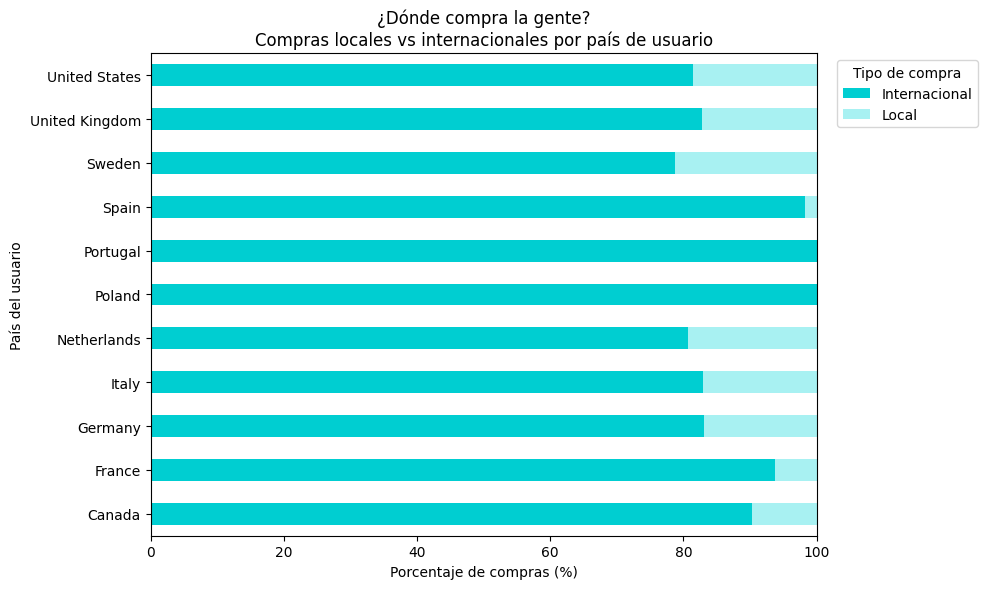

In [ ]:
## Generar gráfico_a "Compras locales vs internacionales por país de usuario"
import matplotlib.pyplot as plt

pivot_grafico_users = pivot_grafico_users.rename(
    columns={False: "Internacional", True: "Local"}
)

grafico_a = pivot_grafico_users.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 6),
    color=["#00CED1", "#A8F1F2"]
)


grafico_a.set_title("¿Dónde compra la gente?\nCompras locales vs internacionales por país de usuario")
grafico_a.set_xlabel("Porcentaje de compras (%)")
grafico_a.set_ylabel("País del usuario")

grafico_a.legend(
    title="Tipo de compra",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.xlim(0, 100)
plt.show()

In [ ]:
## Crear pivot table para grafico_b
pivot_grafico_companies = porcentaje_paises.pivot_table(
    index="country_company",
    columns="local_purchase",
    values="proportion"
)

pivot_grafico_companies

local_purchase,False,True
country_company,,
Australia,100.00,NaN
Belgium,100.00,NaN
Canada,53.85,46.15
China,100.00,NaN
France,89.07,10.93
Germany,88.85,11.15
Ireland,100.00,NaN
Italy,89.15,10.85
Netherlands,88.40,11.60


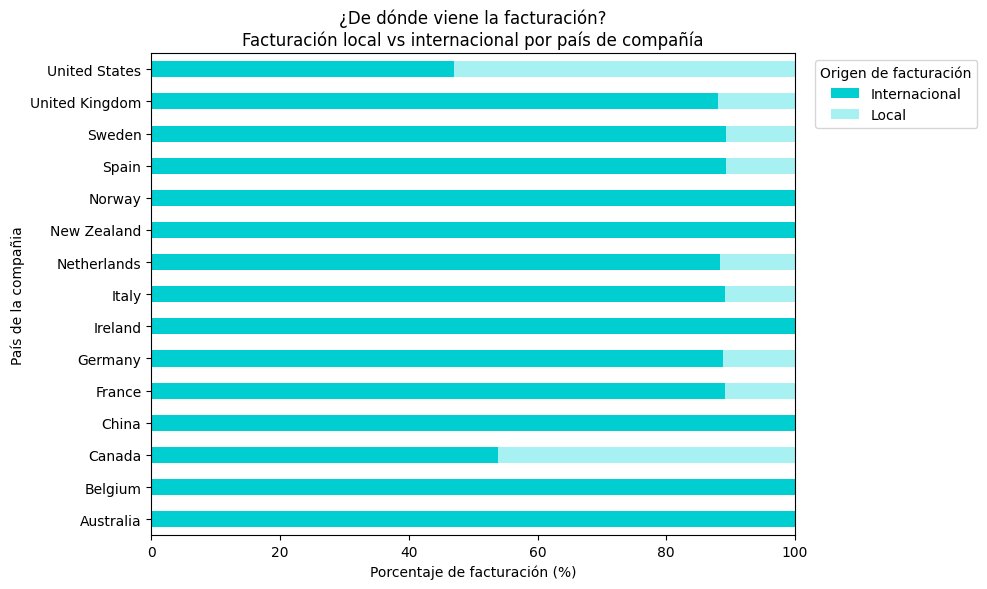

In [ ]:
## Generar gráfico_b "Facturación local vs internacional por país de compañía"
pivot_grafico_companies = pivot_grafico_companies.rename(
    columns={False: "Internacional", True: "Local"}
)

grafico_b = pivot_grafico_companies.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 6),
    color=["#00CED1", "#A8F1F2"]
)

grafico_b.set_title("¿De dónde viene la facturación?\nFacturación local vs internacional por país de compañía")
grafico_b.set_xlabel("Porcentaje de facturación (%)")
grafico_b.set_ylabel("País de la compañia")

grafico_b.legend(
    title="Origen de facturación",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.xlim(0, 100)
plt.show()

### 💡 Análisis de resultados

- **¿En qué países valdría la pena abrir más compañías locales?**

Principalmente en España, ya que es uno de los países con mayor demanda y alrededor del 98% de sus compras se realizan de forma internacional. USA y UK también podrían ser interesantes, ya que están entre los tres países con mayor demanda y, aunque el porcentaje de compras internacionales es algo menor, sigue siendo bastante alto, entre el 81% y el 82%.

- **¿Hay países con demanda pero poca oferta local?**

España vuelve a destacar, ya que tiene una demanda alta pero muy pocas compras se realizan de forma local. También ocurre en Polonia y Portugal, donde el 100% de las compras se realizan de forma internacional. Esto no permite saber directamente si existen pocas compañías locales, pero sí muestra que la demanda de estos países no está siendo cubierta por compañías del mismo país.

- **¿El negocio depende demasiado de compañías de un solo país?**

No existe una dependencia excesiva de compañías de un único país. Suecia es el país con mayor peso en la facturación total, con un 16,83%, seguido de Países Bajos (15,40%), Reino Unido (14,01%), Italia (13,99%) y Alemania (13,73%).

Sin embargo, estos cinco países concentran en conjunto aproximadamente el 74% de la facturación total, por lo que sí existe una dependencia importante de este grupo de países, aunque no de uno solo en concreto. El resto de países tienen un peso bastante menor de forma individual.

- **¿Abrir compañías locales reduciría la fricción o mejoraría la conversión?**

Con los datos actuales, no se puede concluir que abrir más compañías locales vaya a reducir de forma significativa la fricción o mejorar la conversión. El porcentaje de transacciones rechazadas es muy similar entre las compras internacionales (0,90%) y las locales (0,81%), con una diferencia de solo 0,09 puntos porcentuales. Por tanto, los datos no muestran una diferencia relevante en la tasa de rechazo según el tipo de compra.